# Milestone 5: New Data Ingestion, Drift and Re-training

**Trans-Boundary Smog Prediction: Crop Fires and Climate Traps across Punjab (Pakistan and India)**
Munir Tariq (10067), Ismail Nooruddin (09958), Bilal Ayub (09716)

- **Goal:** add the 2024 data wave (Extension 1 of our proposal), test whether the feature distributions and the feature–spike relationship shifted, and check whether the Milestone 4 alert still works and stays fair.
- **New data:** the 2024 records of all three streams for the same 11 cities: Open-Meteo air quality, Open-Meteo weather and NASA VIIRS fire detections (`NASA - 2024 - India.csv`, `NASA-2024.csv`).
- **Code:** `src/ingest.py` (raw files → daily tables, with the frozen Milestone 2 parameters), `src/merge.py` (master table), `src/drift.py` (KS, χ², PSI, domain classifier, concept-drift test), plus `src/modeling.py`, `src/evaluate.py` and `src/fairness.py` from Milestones 3–4.
- **Run:** Kernel > Restart and Run All, from the repository root (about 1.5–2.5 hours on 8 cores). Seeds are fixed. Setting the environment variable `M5_FAST=1` gives a quick debugging run with fewer folds, draws and bootstrap samples; the submitted results use the full run.
- **Rules:**
  - The label is frozen: index weights, z-score parameters and city spike thresholds come from 2022–23 training (`Dataset/clean/aq_params.json`). One sensitivity run re-learns the thresholds (M5.10).
  - Zero-shot = the saved Milestone 4 models and thresholds, applied unchanged.
  - Re-training fits, tunes and sets thresholds on rows up to 2024-08-31 only. Sep–Dec 2024 is the held-out test season.

| Section | Content | Rubric part |
|---|---|---|
| M5.1 | Automated ingestion of the 2024 wave; schema reconciliation; quality audit | 1 |
| M5.2 | Reproduction check: the same code rebuilds the committed 2022–23 tables | 1 |
| M5.3 | Expanded master table: N_total = N_initial + N_new, P_total | 1 |
| M5.4 | Covariate shift: KS, χ², PSI, season-matched tests, domain classifier | 2 |
| M5.5 | Label shift and concept drift; calibration over time | 2 |
| M5.6 | Zero-shot test of the Milestone 4 models on 2024 | 3 |
| M5.7 | Re-training of baseline and advanced models with the purged stratified CV | 3 |
| M5.8 | Three-way comparison table and paired differences | 3 |
| M5.9 | Fairness shift by country and city-size tier; population exposure | 4 |
| M5.10 | Sensitivity: spike thresholds re-learned on the expanded training rows | 2, 4 |
| M5.11 | Saved models and parameters | 4 |
| Summary | Findings, FATEN update and living-lab notes | 4 |

In [1]:
# ------------------------------------------------------------
# Setup: imports, paths and settings
# ------------------------------------------------------------
import json
import os
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOT = Path.cwd()                          # run from the repository root
sys.path.append(str(ROOT))

import joblib
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve
from src import config as C                # shared rules, file names and the Milestone 5 windows
from src import ingest as IG               # raw files -> daily tables (frozen parameters)
from src import merge as M                 # master table
from src import modeling as MD             # data access, CV, pipelines, search, thresholds
from src import evaluate as EV             # metrics, bootstrap, cost curve
from src import fairness as FA             # groups, fairness metrics, mitigation
from src import drift as DR                # KS, chi-square, PSI, domain classifier, concept test
from src import plotting as P              # one figure style for every figure
from src.evaluate import save_table

P.set_style()
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
T0 = time.time()

FAST = os.environ.get("M5_FAST") == "1"    # debugging only; the submitted run has FAST = False
H = 1
TARGET = f"target_spike_h{H}"
COST_FN, COST_FP = EV.COST_FN, EV.COST_FP  # 5:1, as in Milestones 3 and 4
N_BOOT = 100 if FAST else 1000
N_ITER = 4 if FAST else MD.N_ITER          # 60 random-search draws, as in Milestone 4
SEEDS = range(1) if FAST else range(5)     # 5 x 5 = 25 purged folds
EPS_HEADLINE = 0.05                        # fairness band of the Milestone 4 headline mitigation
MASTER_M5 = C.CLEAN_DIR / "master_daily_m5.parquet"

frozen = IG.load_frozen_params()           # aq, weather, fire, role2 (all learned on 2022-08-04 to 2023-08-31)
m3 = json.loads((C.CLEAN_DIR / "m3_params.json").read_text())
m4 = json.loads((C.CLEAN_DIR / "m4_params.json").read_text(encoding="utf-8"))
assert frozen["role2"]["fire_setting"]["tag"] == "up45_r300" and m4["final_model"] == "lr_full"

WAVE_LABEL = {"initial": "Initial wave (Aug 2022–Dec 2023)", "new": "New wave (2024)"}
WAVE_COLOR = {"initial": P.CAT_COLORS[0], "new": P.CAT_COLORS[1]}
SETS = list(MD.FEATURE_SETS)
SET_LABEL = {"full": "full", "weather_only": "weather-only", "no_fire": "no-fire"}
FAM_LABEL = {"lr": "LR", "dt": "DT", "rf": "RF", "hgb": "HGB"}
LABEL = {"majority": "Majority class", "persistence": "Persistence",
         **{f"{f}_{s}": f"{FAM_LABEL[f]} {SET_LABEL[s]}" for f in FAM_LABEL for s in SETS}}
COLOR = {"persistence": "#000000", "majority": P.GREY,
         **{f"{f}_{s}": c for f, c in zip(FAM_LABEL, P.CAT_COLORS) for s in SETS}}
print("FAST run" if FAST else "Full run", "| raw window", C.M5_RAW_START, "to", C.M5_WINDOW_END,
      "| model window", C.M5_WINDOW_START, "to", C.M5_WINDOW_END)

Full run | raw window 2022-01-01 to 2024-12-29 | model window 2022-08-04 to 2024-12-29


---
## M5.1 Automated ingestion of the 2024 wave

- **One pipeline for both waves.** `src/ingest.py` reads every raw file, applies the Role 1 cleaning step for step and writes the daily tables to `Dataset/clean/m5/`. Nothing is typed by hand and no file is edited.
- **Frozen parameters.** The 2024 rows get the z-scores, log decisions, index weights and spike thresholds learned on 2022–23 training. Re-learning them would move the label itself and hide the drift we want to measure.
- **Schema reconciliation.** The table below lists every raw file (format, header, column order, rows, coverage of 2024) and the action taken for each difference between files.

In [2]:
schema = IG.schema_report()
for c in ["first_hour_utc", "last_hour_utc", "first_hour_with_data_utc", "last_hour_with_data_utc"]:
    schema[c] = schema[c].astype(str)                    # written as text (no rounding of dates)
_ = save_table(schema, "m5_schema", index=False)
print(schema[["stream", "city", "file", "format", "timezone", "rows", "first_hour_with_data_utc",
              "last_hour_with_data_utc", "duplicate_hours", "new_wave_coverage_pct"]].to_string(index=False))

# Distinct raw column orders per stream (renaming is by name, so order differences are harmless)
orders = schema.groupby(["stream", "column_order"])["file"].apply(lambda s: ", ".join(s)).reset_index()
print("\nRaw column orders:")
for _, r in orders.iterrows():
    print(f"  {r.stream:12s} {r.column_order}\n  {'':12s} -> {r.file}")

lud_wx = schema[(schema.stream == "weather") & (schema.city == "Ludhiana")].iloc[0]
actions = pd.DataFrame([
    ("Two file formats", "Ludhiana AQ and weather are .xlsx; the other 20 files are .csv",
     "One reader chooses read_excel or read_csv by the file suffix"),
    ("Column order differs", "Pakistani AQ files: NO2, SO2, O3, CO; Indian AQ files: CO, NO2, SO2, O3; "
     "Ludhiana weather lists humidity before rain",
     "Columns are renamed by name (prefix match), never by position"),
    ("Units in column names", "μg/m³, °C, km/h, %, mm in every file of a stream",
     "Short names keep the unit as a suffix (pm2_5_ugm3, temp_c); units checked identical"),
    ("Time zone", "Open-Meteo headers say GMT (offset 0); VIIRS acq_date and acq_time are UTC",
     "+5 h is added before taking the date, for every stream (UTC+5 for Indian cities too; known limitation)"),
    ("File names", "'Sailkot-Weather.csv' (typo), 'Rawalpindi weather.csv', 'NASA-2024.csv' (no spaces)",
     "Mapped in src/config.py; no file is renamed (decision D11)"),
    ("VIIRS time as text", "acq_time such as '0833' loses its leading zero if read as a number",
     "Read as text and zero-padded to 4 digits"),
    ("AQ empty before 2022-08-04", "Every pollutant is empty from January to 3 August 2022",
     "All-empty hours are dropped; the modelling window starts on 2022-08-04"),
    ("Ludhiana weather ends early",
     f"Last hour {lud_wx.last_hour_with_data_utc} UTC (= 30 Dec 04:00 local); every other file runs to 2026",
     "The window ends on 2024-12-29, the last day every stream covers for every city"),
    ("VIIRS days without any detection", "No detection anywhere in India or Pakistan on some UTC dates (see the audit)",
     "Flagged as fire_gap_day; counts stay 0 as in 2022-23; one sensitivity run drops the affected rows"),
    ("Static and offshore VIIRS sources", "type 2 (static) and type 3 (offshore) detections in both files",
     "Only type 0 (vegetation fire) is kept, as in fire.ipynb"),
    ("Data types", "Excel cells load as datetimes, CSV cells as text; fire confidence is a letter",
     "Times parsed to datetime64; keys normalised by merge.normalise_keys (city text, date at midnight)"),
], columns=["issue", "evidence", "action"])
_ = save_table(actions, "m5_schema_actions", index=False)
print()
print(actions.to_string(index=False))

     stream           city                         file format                 timezone   rows first_hour_with_data_utc last_hour_with_data_utc  duplicate_hours  new_wave_coverage_pct
air quality         Lahore             Lahore - Air.csv    csv                      GMT  41208               2022-08-04     2026-09-18 00:00:00                0             100.000000
air quality     Faisalabad         Faisalabad - Air.csv    csv                      GMT  41208               2022-08-04     2026-09-18 00:00:00                0             100.000000
air quality         Multan             Multan - Air.csv    csv                      GMT  41208               2022-08-04     2026-09-18 00:00:00                0             100.000000
air quality     Rawalpindi         Rawalpindi - Air.csv    csv                      GMT  41208               2022-08-04     2026-09-18 00:00:00                0             100.000000
air quality        Sialkot            Sialkot - Air.csv    csv                  

In [3]:
# Run the whole ingestion for the raw window 2022-01-01 to 2024-12-29 (the 2022 lead-in feeds the lags)
t = time.time()
aq, aq_hourly = IG.build_aq(C.M5_RAW_START, C.M5_WINDOW_END, frozen["aq"])
wx, wind, wx_hourly = IG.build_weather(C.M5_RAW_START, C.M5_WINDOW_END, frozen["weather"])
fire_wide, fire_long, gaps, fire_audit = IG.build_fire(C.M5_RAW_START, C.M5_WINDOW_END, wind, frozen["fire"],
                                                       years=(2022, 2023, 2024))
written = IG.write_clean(C.M5_CLEAN_DIR, aq, wx, wind, fire_wide, fire_long, frozen)
print(f"Ingestion done in {time.time() - t:.0f} s -> {C.M5_CLEAN_DIR}: {written}")
print(f"aq_daily {aq.shape}, wx_daily {wx.shape}, wind_daily {wind.shape}, fire_daily {fire_wide.shape}, "
      f"fire_daily_long {fire_long.shape}")
print("\nVIIRS filters (all three years):")
print(fire_audit.to_string(index=False))

# Quality audit, initial wave vs new wave
WAVES = {"initial": (C.M5_WINDOW_START, "2023-12-31"), "new": (C.NEW_WAVE_START, C.M5_WINDOW_END)}
aq_clean = IG.aq_clean_hourly(aq_hourly)
rows = []
for w, (a, b) in WAVES.items():
    inw = lambda d: d["date"].between(pd.Timestamp(a), pd.Timestamp(b))
    h, hc, d = aq_hourly[inw(aq_hourly)], aq_clean[inw(aq_clean)], aq[inw(aq)]
    days = 11 * ((pd.Timestamp(b) - pd.Timestamp(a)).days + 1)
    whr, wd, fw = wx_hourly[inw(wx_hourly)], wx[inw(wx)], fire_wide[inw(fire_wide)]
    g = gaps[gaps["date"].between(pd.Timestamp(a), pd.Timestamp(b))]
    rows += [
        {"stream": "AQ", "check": "city-days expected (11 cities x days)", w: days},
        {"stream": "AQ", "check": "city-days kept (>= 18 valid hours)", w: len(d)},
        {"stream": "AQ", "check": "hourly PM2.5 values missing before cleaning", w: int(h["pm2_5_ugm3"].isna().sum())},
        {"stream": "AQ", "check": "pollutant cells filled by interpolation (gaps <= 6 h)",
         w: int(h[IG.POLLUTANTS].isna().sum().sum() - hc[IG.POLLUTANTS].isna().sum().sum())},
        {"stream": "AQ", "check": "suspect dates (any hour with PM2.5 < 2 ug/m3)", w: int(d.loc[d.suspect_day == 1, "date"].nunique())},
        {"stream": "AQ", "check": "spike days today (frozen thresholds)", w: int(d["smog_spike"].sum())},
        {"stream": "weather", "check": "hourly values missing", w: int(whr[IG.WX_VALUES].isna().sum().sum())},
        {"stream": "weather", "check": "city-days with fewer than 24 hours", w: int((wd["n_hours"] < 24).sum())},
        {"stream": "weather", "check": "stagnant city-days", w: int(wd["stagnant"].sum())},
        {"stream": "weather", "check": "rain city-days", w: int(wd["rain_day"].sum())},
        {"stream": "fire", "check": "dates with no VIIRS detection in India or Pakistan (fire_gap_day)", w: int(g["fire_gap_day"].sum())},
        {"stream": "fire", "check": "dates with no detection in the Pakistan file only", w: int((g.no_detection_pk & ~g.no_detection_in).sum())},
        {"stream": "fire", "check": "upwind fires within 300 km, sum over city-days (main version)",
         w: int(fire_long[(fire_long.cone == "up45") & (fire_long.radius_km == 300) & (fire_long.origin == "ALL")
                          & fire_long["date"].between(pd.Timestamp(a), pd.Timestamp(b))]["fire_count"].sum())},
    ]
quality = pd.DataFrame(rows).groupby(["stream", "check"], sort=False).first().reset_index()
_ = save_table(quality, "m5_quality_audit", index=False)
print("\nQuality audit")
print(quality.to_string(index=False))
gap_dates = gaps.loc[gaps.fire_gap_day == 1, "date"]
print("\nfire_gap_day dates:", ", ".join(d.strftime("%Y-%m-%d") for d in gap_dates))

Ingestion done in 21 s -> Dataset\clean\m5: ['aq_daily.parquet', 'aq_params.json', 'fire_daily.parquet', 'fire_daily_long.parquet', 'fire_zscore_params.json', 'role2_params.json', 'weather_zscore_params.json', 'wind_daily.parquet', 'wx_daily.parquet']
aq_daily (9669, 55), wx_daily (11856, 40), wind_daily (11856, 9), fire_daily (12034, 60), fire_daily_long (902550, 8)

VIIRS filters (all three years):
                                       step  rows_before  rows_after
              bounding box 26-37 N, 68-79 E      1903628      425638
                   type 0 (vegetation fire)       425638      414964
          confidence n and h (main version)       414964      349052
local date inside the window (main version)       349052      348785



Quality audit
 stream                                                             check  initial      new
     AQ                             city-days expected (11 cities x days)   5665.0   4004.0
     AQ                                city-days kept (>= 18 valid hours)   5665.0   4004.0
     AQ                       hourly PM2.5 values missing before cleaning     55.0      0.0
     AQ             pollutant cells filled by interpolation (gaps <= 6 h)    385.0      0.0
     AQ                     suspect dates (any hour with PM2.5 < 2 ug/m3)      4.0      0.0
     AQ                              spike days today (frozen thresholds)    297.0    370.0
weather                                             hourly values missing      0.0      0.0
weather                                city-days with fewer than 24 hours      0.0      0.0
weather                                                stagnant city-days    631.0    466.0
weather                                                    rain c

**What we found (M5.1)**

- **The 2024 wave is complete for air quality and weather.** All 4,004 city-days (11 cities, 1 Jan–29 Dec 2024) keep at least 18 valid hours. No PM2.5 hour is missing, no cell needed interpolation and no day is suspect.
- **The window ends on 29 Dec 2024.** The Ludhiana weather file stops at 23:00 UTC on 29 Dec, so every stream stops there.
- **VIIRS has more gaps in 2024.** On 20 dates of 2024 no fire is detected anywhere in India or Pakistan, against 8 in the initial wave. The gaps include 3–5 November, inside the burning season. We flag them as `fire_gap_day` and keep the counts at 0, as in 2022–23.
- **Fewer upwind fires burned.** The upwind fire total over all city-days fell from 295,943 (initial wave) to 183,953 (2024).
- **The schema needed 11 reconciliation actions** (`m5_schema_actions.csv`). Columns are renamed by name, never by position, and every clock is shifted to UTC+5 before taking the date.

---
## M5.2 Reproduction check

The ingestion is only trustworthy for 2024 if it reproduces what the Role 1 notebooks produced for 2022–23. We check this in three ways:
1. **Rebuild only 2022–23** and compare every cell with the committed `Dataset/clean` tables.
2. **Compare the 2024 run's 2022–23 rows** with the same tables. Adding 2024 must not change the initial wave.
3. **Re-learn the parameters** (z-scores, log decisions, thresholds) on the training rows and compare them with the frozen JSON files.

In [4]:
t = time.time()
aq0, _ = IG.build_aq("2022-01-01", "2023-12-31", frozen["aq"])
wx0, wind0, _ = IG.build_weather("2022-01-01", "2023-12-31", frozen["weather"])
fw0, fl0, _, _ = IG.build_fire("2022-01-01", "2023-12-31", wind0, frozen["fire"], years=(2022, 2023))
print(f"2022-23 rebuild in {time.time() - t:.0f} s")

LONG_KEYS = ("city", "date", "cone", "radius_km", "origin")
tables = [("aq_daily", aq0, aq, ("city", "date")), ("wx_daily", wx0, wx, ("city", "date")),
          ("wind_daily", wind0, wind, ("city", "date")), ("fire_daily", fw0, fire_wide, ("city", "date")),
          ("fire_daily_long", fl0, fire_long, LONG_KEYS)]
LEAD_IN = pd.Timestamp(C.M5_WINDOW_START) - pd.Timedelta(days=3)   # earliest day the master reads
repro_rows = []
for name, rebuilt, extended, keys in tables:
    old = pd.read_parquet(C.CLEAN_DIR / f"{name}.parquet")
    for run, frame in [("rebuild of 2022-23 only", rebuilt),
                       ("2024 run, rows up to 2023-12-31", extended[extended["date"] <= "2023-12-31"])]:
        cmp = IG.compare_frames(frame, old, keys=keys)
        o_in, f_in = old[old["date"] >= LEAD_IN], frame[frame["date"] >= LEAD_IN]
        cmp_in = IG.compare_frames(f_in, o_in, keys=keys)
        repro_rows.append({"table": name, "run": run, "rows": len(frame), "columns_compared": len(cmp),
                           "cells_differing": int(cmp.differing_cells.sum()),
                           "columns_differing": ", ".join(cmp.loc[cmp.differing_cells > 0, "column"]) or "none",
                           "cells_differing_from_lead_in": int(cmp_in.differing_cells.sum()),
                           "max_abs_diff": float(cmp["max_abs_diff"].max())})
        assert cmp_in.differing_cells.sum() == 0, f"{name} ({run}) differs inside the modelling window"
repro = pd.DataFrame(repro_rows)
print(repro.to_string(index=False))

# Where the only differences lie (outside the modelling window)
old_wx = pd.read_parquet(C.CLEAN_DIR / "wx_daily.parquet").sort_values(["city", "date"]).reset_index(drop=True)
new_wx = wx0.sort_values(["city", "date"]).reset_index(drop=True)
diff = old_wx[old_wx["rain_day"].to_numpy() != new_wx["rain_day"].to_numpy()][["city", "date", "precip_sum_mm", "rain_day"]]
print("\nrain_day cells that differ from the committed table:")
print(diff.assign(rebuilt_rain_day=new_wx.loc[diff.index, "rain_day"].to_numpy()).to_string(index=False))

# Frozen parameters against the values the training rows give
la, lw, lf = IG.learn_aq_params(aq), IG.learn_weather_params(wx), IG.learn_fire_params(fire_wide)
fz = frozen["aq"]
frozen_check = pd.DataFrame([
    {"parameter set": "AQ z-score mean and SD (13 columns)", "values": 26,
     "max_abs_diff": max(abs(la["zscore"][c][k] - fz["zscore"][c][k]) for c in la["zscore"] for k in ("mean", "std"))},
    {"parameter set": "AQ log1p decisions (13 columns)", "values": 13,
     "max_abs_diff": float(sum(la["zscore"][c]["log1p"] != fz["zscore"][c]["log1p"] for c in la["zscore"]))},
    {"parameter set": "spike thresholds, mean index (11 cities)", "values": 11,
     "max_abs_diff": max(abs(la["spike_threshold_mean_index"][c] - fz["spike_threshold_mean_index"][c]) for c in C.CITY_COUNTRY)},
    {"parameter set": "spike thresholds, max index (11 cities)", "values": 11,
     "max_abs_diff": max(abs(la["spike_threshold_max_index"][c] - fz["spike_threshold_max_index"][c]) for c in C.CITY_COUNTRY)},
    {"parameter set": "weather z-score mean and SD (10 columns)", "values": 20,
     "max_abs_diff": max(abs(lw[c][k] - frozen["weather"][c][k]) for c in lw for k in ("mean", "std"))},
    {"parameter set": "fire log1p z-score mean and SD (10 columns)", "values": 20,
     "max_abs_diff": max(abs(lf[c][k] - frozen["fire"][c][k]) for c in lf for k in ("mean", "std"))},
])
assert (frozen_check["max_abs_diff"] < 1e-9).all()
print()
print(frozen_check.to_string(index=False))

2022-23 rebuild in 15 s


          table                             run   rows  columns_compared  cells_differing columns_differing  cells_differing_from_lead_in  max_abs_diff
       aq_daily         rebuild of 2022-23 only   5665                53                0              none                             0  1.136868e-13
       aq_daily 2024 run, rows up to 2023-12-31   5665                53                0              none                             0  1.136868e-13
       wx_daily         rebuild of 2022-23 only   7852                38                1          rain_day                             0  1.000000e+00
       wx_daily 2024 run, rows up to 2023-12-31   7852                38                1          rain_day                             0  1.000000e+00
     wind_daily         rebuild of 2022-23 only   7852                 7                0              none                             0  1.307399e-12
     wind_daily 2024 run, rows up to 2023-12-31   7852                 7                

**What we found (M5.2)**

- **The automated pipeline reproduces Role 1's work.** Rebuilding 2022–23 gives every committed daily table (AQ, weather, wind, fire wide and long) with 0 differing cells inside the modelling window.
- **One rain-day flag differs outside the window** (Ludhiana, 26 Jan 2022). Floating-point summation order puts the daily rain at 0.9999999999999999 mm. Rounding to 6 decimals fixes the 2022–23 cells (decision N3).
- **The master differs only where 2024 now exists.** Up to 28 Dec 2023 the master matches exactly. The next-day targets of 29–31 Dec 2023 now point into 2024 instead of being empty.
- **The frozen parameters are the training parameters.** Re-learning them on the 2022–23 training rows gives the same values to floating-point precision (`m5_frozen_check.csv`).

---
## M5.3 Expanded master table

- `merge.build_master` runs unchanged on `Dataset/clean/m5/`, with the seal moved on purpose from 2024-01-01 to 2025-01-01 (`sealed_from`).
- **Re-training split** (column `split`): train 2022-08-04 → 2024-08-31, skip 2024-09-01 → 09-03 (3 days = longest horizon), test 2024-09-04 → 2024-12-29.
- **New columns:**
  - `wave` (initial / new);
  - `split_initial` (the Milestone 3–4 train / skip / validation split, or "new wave");
  - `fire_gap_day` and `fire_gap_affected` (a gap day on t, t−1, t−2 or t−3, the days the fire lags read).
- The fire-setting z-scores use the initial training rows, so they equal `role2_params.json`.

In [5]:
fs = frozen["role2"]["fire_setting"]
master, mlog = M.build_master(C.M5_WINDOW_START, C.M5_WINDOW_END, C.M5_TRAIN_START, C.M5_TRAIN_END,
                              C.M5_SKIP_START, C.M5_SKIP_END, C.M5_TEST_START, C.M5_TEST_END,
                              clean_dir=C.M5_CLEAN_DIR, sealed_from=C.SEAL_M5)
for cone in [fs["cone"], "none", "down45"]:
    master = M.add_fire_setting(master, cone, fs["radius_km"], C.M5_WINDOW_START, C.M5_WINDOW_END,
                                lag_origins=("all", "in", "pk") if cone == fs["cone"] else ("all",),
                                clean_dir=C.M5_CLEAN_DIR)
init_train = master["date"].between(pd.Timestamp(C.TRAIN_START), pd.Timestamp(C.TRAIN_END))
new_cnt = [f"fire_cnt_{t}_{o}" for t in ["up45_r300", "r300", "down45_r300"] for o in ["all", "in", "pk"]]
master, fire_scale = M.add_log_z(master, new_cnt, init_train)
assert max(abs(fire_scale[k][q] - frozen["role2"]["fire_log1p_zscore"][k][q]) for k in fire_scale for q in ("mean", "std")) < 1e-9

old_master = pd.read_parquet(C.CLEAN_DIR / "master_daily.parquet")
assert list(master.columns) == list(old_master.columns), "column order differs from the Milestone 2 master"
d = master["date"]
master["split"] = master["split"].replace({"validation": "test"})
master["wave"] = np.where(d >= pd.Timestamp(C.NEW_WAVE_START), "new", "initial")
master["split_initial"] = np.select(
    [d.between(pd.Timestamp(C.TRAIN_START), pd.Timestamp(C.TRAIN_END)),
     d.between(pd.Timestamp(C.SKIP_START), pd.Timestamp(C.SKIP_END)),
     d.between(pd.Timestamp(C.VALID_START), pd.Timestamp(C.VALID_END))], ["train", "skip", "validation"], "new wave")
gap_set = set(gaps.loc[gaps.fire_gap_day == 1, "date"])
master["fire_gap_day"] = d.isin(gap_set).astype("int8")
master["fire_gap_affected"] = d.isin({g + pd.Timedelta(days=k) for g in gap_set for k in range(4)}).astype("int8")

# The initial wave inside the new master must equal the Milestone 2 master (apart from the split and the
# targets of 29-31 Dec 2023, which now point into 2024 instead of being empty)
cmp = IG.compare_frames(master[d <= "2023-12-28"][old_master.columns], old_master[old_master.date <= "2023-12-28"],
                        skip=("split", "is_train"))
assert cmp.differing_cells.sum() == 0
cmp_all = IG.compare_frames(master[d <= "2023-12-31"][old_master.columns], old_master, skip=("split", "is_train"))
repro = pd.concat([repro, pd.DataFrame([
    {"table": "master_daily", "run": "2024 run, rows up to 2023-12-28", "rows": int((d <= "2023-12-28").sum()),
     "columns_compared": len(cmp), "cells_differing": int(cmp.differing_cells.sum()), "columns_differing": "none",
     "cells_differing_from_lead_in": int(cmp.differing_cells.sum()), "max_abs_diff": float(cmp.max_abs_diff.max())},
    {"table": "master_daily", "run": "2024 run, rows up to 2023-12-31", "rows": int((d <= "2023-12-31").sum()),
     "columns_compared": len(cmp_all), "cells_differing": int(cmp_all.differing_cells.sum()),
     "columns_differing": ", ".join(cmp_all.loc[cmp_all.differing_cells > 0, "column"]) or "none",
     "cells_differing_from_lead_in": int(cmp_all.differing_cells.sum()), "max_abs_diff": float(cmp_all.max_abs_diff.max())}])],
    ignore_index=True)
_ = save_table(repro, "m5_reproduction", index=False)
_ = save_table(frozen_check, "m5_frozen_check", index=False)
print(repro.tail(2).to_string(index=False))

master.to_parquet(MASTER_M5, index=False)
dic = M.data_dictionary(master[old_master.columns])
dic.loc[dic.column == "split", "meaning"] = "Re-training split: train (to 2024-08-31) / skip / test (2024-09-04 to 2024-12-29)"
extra = pd.DataFrame([
    ("wave", "initial (2022-08-04 to 2023-12-31) or new (2024)", "category"),
    ("split_initial", "Milestone 3-4 split: train / skip / validation, or 'new wave' for 2024", "category"),
    ("fire_gap_day", "1 if no VIIRS detection exists anywhere in India or Pakistan on that date", "0/1"),
    ("fire_gap_affected", "1 if a fire_gap_day falls on day t, t-1, t-2 or t-3 (the days the fire lags read)", "0/1"),
], columns=["column", "meaning", "unit"]).assign(source="derived in data_extension.ipynb", owner="M5")
extra["dtype"] = [str(master[c].dtype) for c in extra.column]
extra["missing"] = [int(master[c].isna().sum()) for c in extra.column]
dic = pd.concat([dic, extra[dic.columns]], ignore_index=True)
dic.to_csv(C.CLEAN_DIR / "master_data_dictionary_m5.csv", index=False)
print(f"Saved {MASTER_M5.name}: {master.shape[0]:,} rows x {master.shape[1]} columns; dictionary {len(dic)} rows")

# Modelling frame (decision D12 drops) and the analysis subsets
frame, drop_log = MD.load_model_frame(H, path=MASTER_M5, sealed_from=C.SEAL_M5)
df = FA.add_groups(frame)
train = df[df["split"] == "train"].reset_index(drop=True)
test = df[df["split"] == "test"].reset_index(drop=True)
init = df[df["wave"] == "initial"].reset_index(drop=True)
new = df[df["wave"] == "new"].reset_index(drop=True)
df4, _ = MD.load_model_frame(H)                                         # the Milestone 3-4 frame, unchanged
val4 = FA.add_groups(df4[df4["split"] == "validation"].reset_index(drop=True))
train4 = FA.add_groups(df4[df4["split"] == "train"].reset_index(drop=True))
assert (len(train4), int(train4[TARGET].sum()), len(val4), int(val4[TARGET].sum())) == (4246, 204, 1298, 89)


def assert_train_only(fr):
    # Called before every fit: only rows of the re-training split up to 2024-08-31 may reach a model
    assert fr["date"].max() <= pd.Timestamp(C.M5_TRAIN_END) and (fr["split"] == "train").all()


n_feat = len(MD.FEATURE_SETS["full"])
dims = []
for name, part, rows_m in [("initial wave", master[master.wave == "initial"], init),
                           ("new wave (2024)", master[master.wave == "new"], new), ("total", master, df)]:
    dims.append({"data": name, "first_date": part.date.min().date(), "last_date": part.date.max().date(),
                 "days": part.date.nunique(), "cities": part.city.nunique(), "city_days_N": len(part),
                 "master_columns_P": master.shape[1], "model_features": n_feat,
                 "model_rows_after_drops": len(rows_m), "spikes_next_day": int(rows_m[TARGET].sum()),
                 "spike_rate": rows_m[TARGET].mean()})
dims = pd.DataFrame(dims)
assert dims.loc[2, "city_days_N"] == dims.loc[0, "city_days_N"] + dims.loc[1, "city_days_N"]
_ = save_table(dims, "m5_dataset_dims", index=False)
_ = save_table(drop_log, "m5_drop_log")
print("\nN_total = N_initial + N_new:", dims.city_days_N.tolist())
print(dims.to_string(index=False))
print("\nRows dropped (decision D12), by re-training split:")
print(drop_log.to_string())

bal = []
for name, part in [("re-training: train", train), ("re-training: test (Sep-Dec 2024)", test),
                   ("initial wave: Milestone 4 train", init[init.split_initial == "train"]),
                   ("initial wave: Milestone 4 validation", init[init.split_initial == "validation"]),
                   ("new wave: Jan-Aug 2024 (in re-training train)", new[new.split == "train"])]:
    bal.append({"rows": name, "city_days": len(part), "first": part.date.min().date(), "last": part.date.max().date(),
                "spikes": int(part[TARGET].sum()), "rate": part[TARGET].mean()})
bal = pd.DataFrame(bal)
_ = save_table(bal, "m5_split_balance", index=False)
print()
print(bal.to_string(index=False))

master: 9,669 rows x 236 columns


       table                             run  rows  columns_compared  cells_differing                                                                                    columns_differing  cells_differing_from_lead_in  max_abs_diff
master_daily 2024 run, rows up to 2023-12-28  5632               283                0                                                                                                 none                             0  1.307399e-12
master_daily 2024 run, rows up to 2023-12-31  5665               283              132 target_index_h1, target_spike_h1, target_index_h2, target_spike_h2, target_index_h3, target_spike_h3                           132  1.307399e-12


Saved master_daily_m5.parquet: 9,669 rows x 291 columns; dictionary 291 rows



N_total = N_initial + N_new: [5665, 4004, 9669]
           data first_date  last_date  days  cities  city_days_N  master_columns_P  model_features  model_rows_after_drops  spikes_next_day  spike_rate
   initial wave 2022-08-04 2023-12-31   515      11         5665               291              42                    5588              301    0.053865
new wave (2024) 2024-01-01 2024-12-29   364      11         4004               291              42                    3960              362    0.091414
          total 2022-08-04 2024-12-29   879      11         9669               291              42                    9548              663    0.069439

Rows dropped (decision D12), by re-training split:
split                skip  test  train
dropped because                       
skip split             33     0      0
missing target          0    11      0
missing feature         0     0     22
suspect feature day     0     0     44
suspect target day      0     0     11

                 

**What we found (M5.3)**

- **N_total = 5,665 + 4,004 = 9,669 city-days, with P_total = 291 master columns.** The model uses the same 42 features as Milestones 3 and 4.
- **After the D12 drops, 9,548 rows remain** (5,588 initial, 3,960 new), with 663 next-day spikes.
- **The 2024 spike rate is higher.** It is 9.1% in 2024 against 5.4% in the initial wave.
- **Re-training split:** 8,272 training rows (483 spikes, 5.8%) to 31 Aug 2024, then a 3-day gap, then 1,276 test rows (180 spikes, 14.1%) from 4 Sep to 28 Dec 2024.

---
## M5.4 Covariate shift (feature drift)

- **Tests:**
  - two-sample **Kolmogorov–Smirnov** (KS) for continuous features;
  - **χ² test of homogeneity** for stagnation, rain and the wind sector;
  - the **Population Stability Index** (PSI) for both. PSI uses 10 bins at the reference deciles, and ties are merged.
- **Corrections and bands:**
  - With about 5,000 rows per wave almost any difference is significant, so p-values get the **Benjamini–Hochberg** correction.
  - PSI gives the size of the shift: < 0.10 stable, 0.10–0.25 moderate, ≥ 0.25 major (the usual credit-scoring bands).
- **Two comparisons:**
  - **whole wave:** initial (Aug 2022–Dec 2023) against new (2024);
  - **season-matched:** Sep–Dec of the initial wave against Sep–Dec 2024. The initial wave holds two Aug–Dec seasons but only one Jan–Jul, so the whole-wave comparison partly measures a different month mix.
- **Joint shift:** a **domain classifier** tries to tell the waves apart from the model features (no month or city columns). Its cross-validated ROC-AUC is 0.5 when the waves look alike.
- **Reference rows:** all tests use the modelling rows (after the D12 drops).

In [6]:
CONT = {"composite_smog_index": "Composite Smog Index (today)",
        "persist_margin": "Index margin over city threshold (today)",
        "pm2_5_mean_ugm3": "PM2.5 daily mean (µg/m³)", "pm10_mean_ugm3": "PM10 daily mean (µg/m³)",
        "no2_mean_ugm3": "NO2 daily mean (µg/m³)", "so2_mean_ugm3": "SO2 daily mean (µg/m³)",
        "o3_mean_ugm3": "O3 daily mean (µg/m³)", "co_mean_ugm3": "CO daily mean (µg/m³)",
        "temp_mean_c": "Mean temperature (°C)", "temp_range_c": "Daily temperature range (°C)",
        "rh_mean_pct": "Relative humidity (%)", "vec_len_kmh": "Vector-mean wind speed (km/h)",
        "precip_sum_mm": "Rain (mm per day)",
        "fire_cnt_up45_r300_all": "Upwind fires, ±45°, 300 km (count)",
        "fire_cnt_r300_all": "All fires within 300 km (count)",
        "fire_cnt_up45_r300_in": "Upwind India-origin fires (count)",
        "fire_cnt_up45_r300_pk": "Upwind Pakistan-origin fires (count)"}
CAT = {"stagnant": "Stagnant air (vector wind < 2 km/h)", "rain_day": "Rain day (≥ 1 mm)",
       "wind_sector": "Wind sector (8 sectors + calm)"}
LABELS = {**CONT, **CAT}
SEASON = [9, 10, 11, 12]
COMPARE = {"whole wave": (init, new),
           "season-matched (Sep-Dec)": (init[init.date.dt.month.isin(SEASON)], new[new.date.dt.month.isin(SEASON)])}

drift = pd.concat([DR.drift_table(a, b, list(CONT), list(CAT), labels=LABELS).assign(comparison=k)
                   for k, (a, b) in COMPARE.items()], ignore_index=True)
_ = save_table(drift, "m5_drift_features", index=False)
show = ["comparison", "label", "test", "statistic", "q_value_bh", "psi", "psi_band", "ref_mean", "new_mean", "std_mean_diff"]
for k in COMPARE:
    print(f"\n{k}: n = {COMPARE[k][0].shape[0]:,} vs {COMPARE[k][1].shape[0]:,} city-days")
    print(drift[drift.comparison == k][show[1:]].round(4).to_string(index=False))


whole wave: n = 5,588 vs 3,960 city-days
                                   label              test  statistic  q_value_bh    psi       psi_band  ref_mean  new_mean  std_mean_diff
            Composite Smog Index (today)                KS     0.0985      0.0000 0.0719         stable    0.0318   -0.0159        -0.0643
Index margin over city threshold (today)                KS     0.0660      0.0000 0.0524         stable   -1.1653   -1.2130        -0.0672
                PM2.5 daily mean (µg/m³)                KS     0.1117      0.0000 0.0940         stable   56.1072   57.6553         0.0494
                 PM10 daily mean (µg/m³)                KS     0.0508      0.0000 0.0330         stable   88.9539   91.2455         0.0491
                  NO2 daily mean (µg/m³)                KS     0.1321      0.0000 0.0917         stable   29.6252   24.5530        -0.2527
                  SO2 daily mean (µg/m³)                KS     0.1161      0.0000 0.0772         stable   12.7012   11.2859 

In [7]:
# PSI month by month (same calendar month in both waves) and by city-size tier (season-matched)
KEY = ["composite_smog_index", "pm2_5_mean_ugm3", "temp_mean_c", "temp_range_c", "rh_mean_pct",
       "vec_len_kmh", "fire_cnt_up45_r300_all", "stagnant"]
mrows = []
for m in range(1, 13):
    a, b = init[init.date.dt.month == m], new[new.date.dt.month == m]
    for f in KEY:
        mrows.append({"month": m, "feature": f, "label": LABELS[f], "psi": DR.psi(a[f], b[f]),
                      "ref_mean": a[f].mean(), "new_mean": b[f].mean(), "n_ref": len(a), "n_new": len(b)})
drift_month = pd.DataFrame(mrows)
_ = save_table(drift_month, "m5_drift_monthly", index=False)
print(drift_month.pivot(index="label", columns="month", values="psi").round(2).to_string())

trows = []
a_s, b_s = COMPARE["season-matched (Sep-Dec)"]
for g in FA.TIER_LABEL.values():
    a, b = a_s[a_s.tier == g], b_s[b_s.tier == g]
    for f in KEY:
        trows.append({"tier": g, "feature": f, "label": LABELS[f], "psi": DR.psi(a[f], b[f]),
                      "ks_stat": stats.ks_2samp(a[f], b[f]).statistic if f != "stagnant" else np.nan,
                      "ref_mean": a[f].mean(), "new_mean": b[f].mean()})
drift_tier = pd.DataFrame(trows)
_ = save_table(drift_tier, "m5_drift_tier", index=False)
print()
print(drift_tier.pivot(index="label", columns="tier", values="psi").round(3).to_string())

month                                  1     2     3     4     5     6     7     8     9     10    11    12
label                                                                                                      
Composite Smog Index (today)         0.73  0.34  0.20  0.47  0.18  0.12  0.46  0.88  0.10  0.10  0.61  0.12
Daily temperature range (°C)         0.39  0.41  0.15  0.04  1.02  0.76  0.56  0.56  0.04  0.26  0.13  0.04
Mean temperature (°C)                0.38  1.57  0.88  0.14  1.12  1.29  1.12  0.25  0.18  0.78  0.38  0.34
PM2.5 daily mean (µg/m³)             0.69  0.31  0.37  0.51  0.32  0.37  0.57  0.87  0.25  0.22  0.70  0.27
Relative humidity (%)                1.08  0.20  0.44  0.13  2.23  2.62  1.33  0.76  0.07  0.45  0.05  0.75
Stagnant air (vector wind < 2 km/h)  0.08  0.00  0.03  0.02  0.01  0.09  0.01  0.04  0.00  0.01  0.23  0.03
Upwind fires, ±45°, 300 km (count)   0.14  0.10  0.10  0.08  0.27  0.24  0.10  0.07  0.57  0.31  0.08  0.21
Vector-mean wind speed (km/h

In [8]:
# Domain classifier (adversarial validation): can the model features tell 2024 from the initial wave?
BLOCKS = {"all model features (no month, no city)": [c for c in MD.FEATURE_SETS["full"] if c not in MD.CALENDAR_PLACE],
          "AQ history": MD.AQ_HISTORY, "weather": MD.WEATHER, "upwind fires": MD.FIRE}
drows, dom_scores = [], {}
for k, (a, b) in COMPARE.items():
    groups = MD.week_groups(pd.concat([a.date, b.date], ignore_index=True))
    for block, cols in BLOCKS.items():
        auc, oof_d, y_d = DR.domain_auc(a[cols], b[cols], groups, n_splits=5, seed=42)
        drows.append({"comparison": k, "features": block, "columns": len(cols), "n_ref": len(a), "n_new": len(b),
                      "cv_roc_auc": auc})
        dom_scores[(k, block)] = (oof_d, y_d)
domain = pd.DataFrame(drows)
_ = save_table(domain, "m5_domain_auc", index=False)
print(domain.round(4).to_string(index=False))

              comparison                               features  columns  n_ref  n_new  cv_roc_auc
              whole wave all model features (no month, no city)       21   5588   3960      0.5305
              whole wave                             AQ history        3   5588   3960      0.5266
              whole wave                                weather       14   5588   3960      0.5168
              whole wave                           upwind fires        4   5588   3960      0.4991
season-matched (Sep-Dec) all model features (no month, no city)       21   2629   1276      0.6445
season-matched (Sep-Dec)                             AQ history        3   2629   1276      0.4909
season-matched (Sep-Dec)                                weather       14   2629   1276      0.5882
season-matched (Sep-Dec)                           upwind fires        4   2629   1276      0.5791


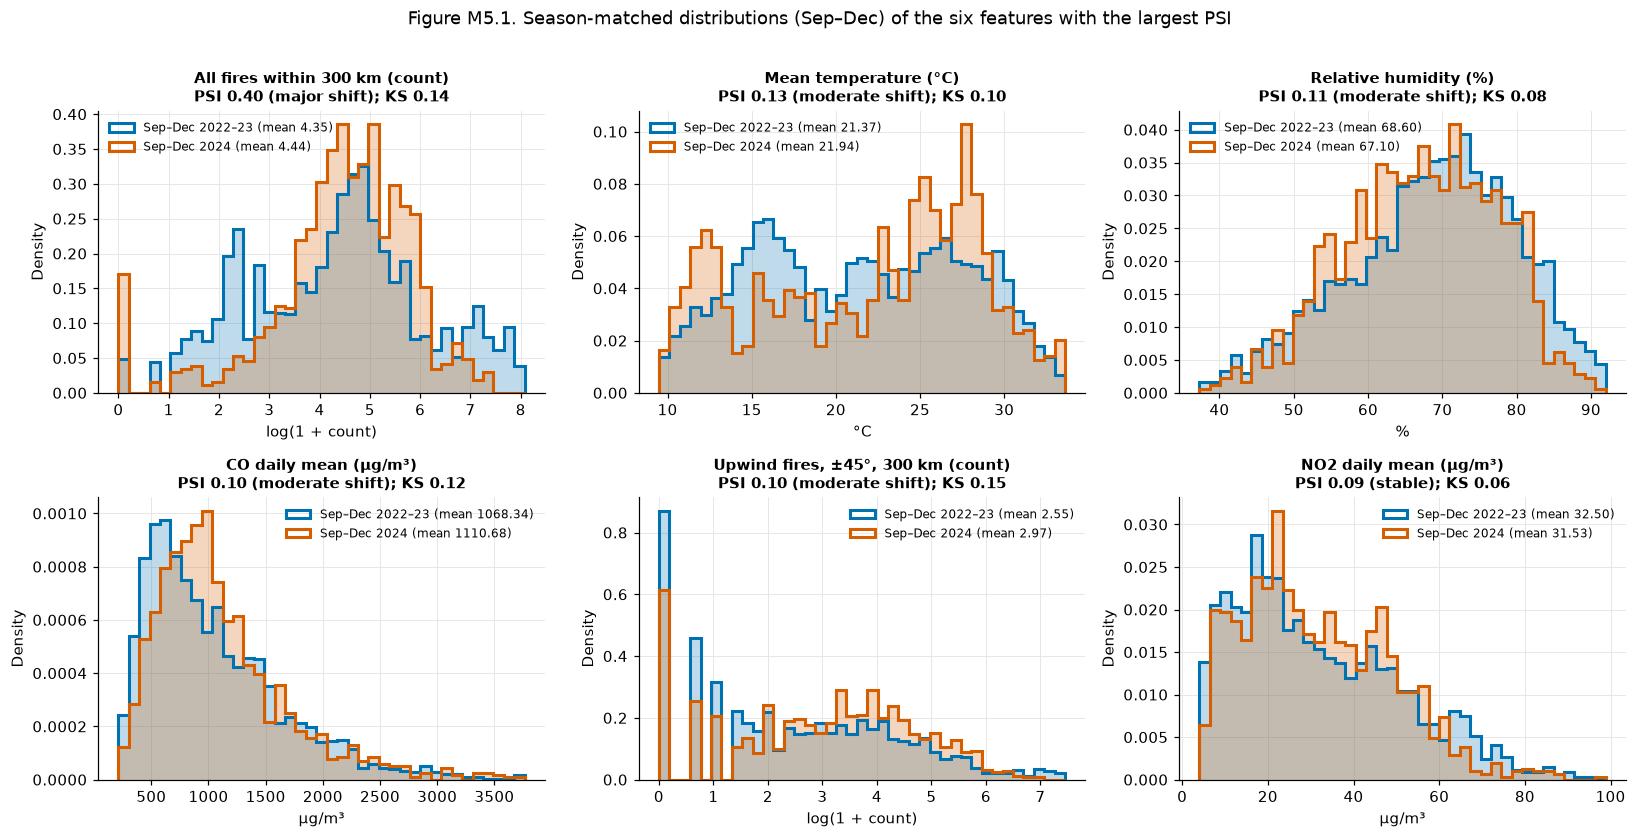

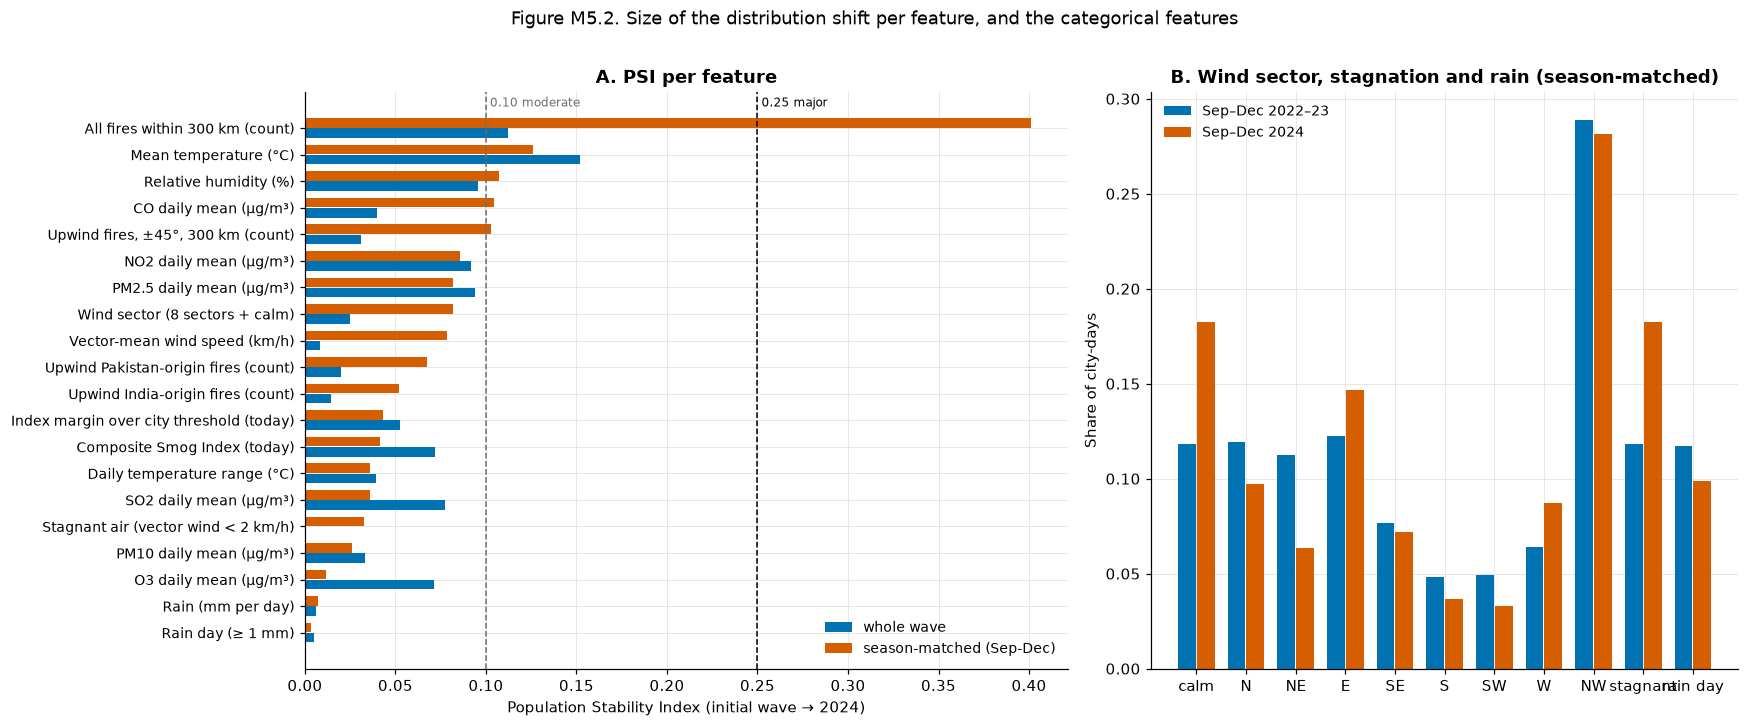

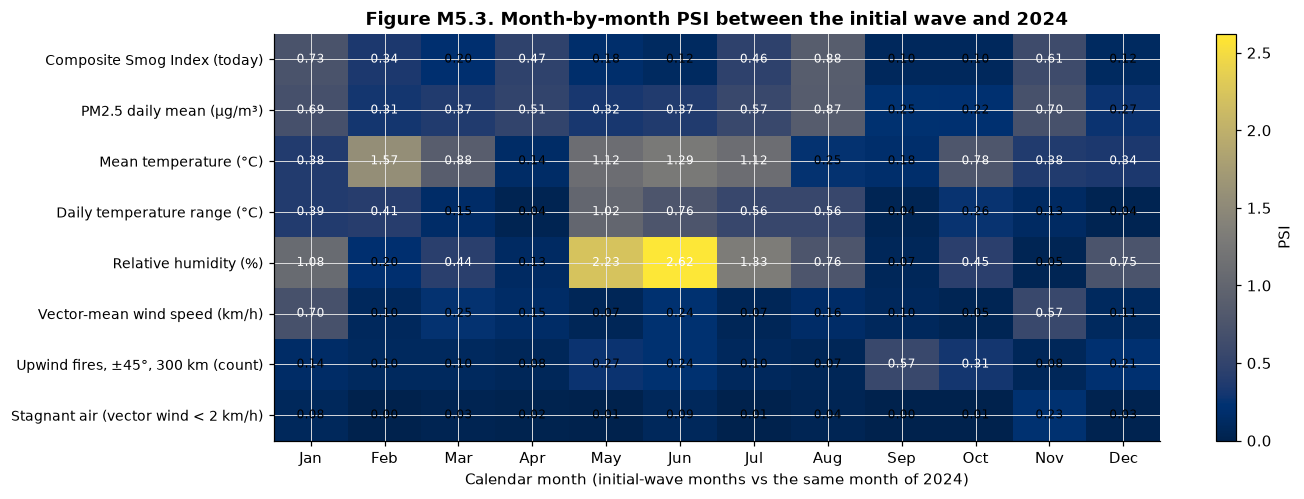

In [9]:
# Figure M5.1: overlaid distributions of the six continuous features with the largest season-matched PSI
sm = drift[(drift.comparison == "season-matched (Sep-Dec)") & (drift.type == "continuous")]
sm = sm[sm.feature != "persist_margin"].sort_values("psi", ascending=False)
top = sm.feature.head(6).tolist()
a_s, b_s = COMPARE["season-matched (Sep-Dec)"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, f in zip(axes.ravel(), top):
    is_fire = f.startswith("fire_")
    tr = (lambda v: np.log1p(v)) if is_fire else (lambda v: v)
    va, vb = tr(a_s[f].astype(float)), tr(b_s[f].astype(float))
    lo, hi = np.nanquantile(np.r_[va, vb], [0.005, 0.995])
    bins = np.linspace(lo, hi, 40)
    for w, v in [("initial", va), ("new", vb)]:
        ax.hist(v, bins=bins, density=True, histtype="stepfilled", alpha=0.25, color=WAVE_COLOR[w])
        ax.hist(v, bins=bins, density=True, histtype="step", lw=2, color=WAVE_COLOR[w],
                label=f"{'Sep–Dec 2022–23' if w == 'initial' else 'Sep–Dec 2024'} (mean {np.nanmean(v):.2f})")
    r = sm.set_index("feature").loc[f]
    ax.set_title(f"{LABELS[f]}\nPSI {r.psi:.2f} ({r.psi_band}); KS {r.statistic:.2f}", fontsize=10)
    ax.set_xlabel(("log(1 + count)" if is_fire else LABELS[f].split(" (")[-1].rstrip(")") if "(" in LABELS[f] else "value"))
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
fig.suptitle("Figure M5.1. Season-matched distributions (Sep–Dec) of the six features with the largest PSI", y=1.01)
fig.tight_layout()
P.save(fig, "fig_m05_1_densities")
plt.show()

# Figure M5.2: PSI of every feature (both comparisons) and the categorical shares
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
order = drift[drift.comparison == "season-matched (Sep-Dec)"].sort_values("psi")["feature"].tolist()
yy = np.arange(len(order))
for k, (cmpn, col) in enumerate([("whole wave", P.CAT_COLORS[0]), ("season-matched (Sep-Dec)", P.CAT_COLORS[1])]):
    v = drift[drift.comparison == cmpn].set_index("feature").loc[order, "psi"]
    axes[0].barh(yy + (k - 0.5) * 0.38, v, height=0.36, color=col, label=cmpn)
axes[0].axvline(0.10, color=P.GREY, ls="--", lw=1)
axes[0].axvline(0.25, color="#000000", ls="--", lw=1)
axes[0].text(0.10, len(order) - 0.3, " 0.10 moderate", fontsize=8, color=P.GREY, va="bottom")
axes[0].text(0.25, len(order) - 0.3, " 0.25 major", fontsize=8, va="bottom")
axes[0].set_yticks(yy); axes[0].set_yticklabels([LABELS[f] for f in order], fontsize=9)
axes[0].set(xlabel="Population Stability Index (initial wave → 2024)", title="A. PSI per feature")
axes[0].legend(loc="lower right", fontsize=9)
cats = ["calm"] + [s for s in M.SECTORS]
share = lambda fr: fr["wind_sector"].value_counts(normalize=True).reindex(cats).fillna(0)
xs = np.arange(len(cats) + 2)
vals = {w: np.r_[share(fr).to_numpy(), fr["stagnant"].mean(), fr["rain_day"].mean()]
        for w, fr in [("initial", a_s), ("new", b_s)]}
for k, w in enumerate(["initial", "new"]):
    axes[1].bar(xs + (k - 0.5) * 0.38, vals[w], width=0.36, color=WAVE_COLOR[w],
                label="Sep–Dec 2022–23" if w == "initial" else "Sep–Dec 2024")
axes[1].set_xticks(xs); axes[1].set_xticklabels([c.upper() if c != "calm" else "calm" for c in cats] + ["stagnant", "rain day"])
axes[1].set(ylabel="Share of city-days", title="B. Wind sector, stagnation and rain (season-matched)")
axes[1].legend(fontsize=9)
fig.suptitle("Figure M5.2. Size of the distribution shift per feature, and the categorical features", y=1.01)
fig.tight_layout()
P.save(fig, "fig_m05_2_psi")
plt.show()

# Figure M5.3: PSI by calendar month
piv = drift_month.pivot(index="label", columns="month", values="psi").loc[[LABELS[f] for f in KEY]]
fig, ax = plt.subplots(figsize=(13, 4.8))
im = ax.imshow(piv.to_numpy(), cmap=P.SEQ_CMAP, aspect="auto", vmin=0, vmax=max(0.5, float(np.nanmax(piv.to_numpy()))))
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.3 else "#000000")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=9)
ax.set(xlabel="Calendar month (initial-wave months vs the same month of 2024)")
fig.colorbar(im, ax=ax, label="PSI")
ax.set_title("Figure M5.3. Month-by-month PSI between the initial wave and 2024")
P.save(fig, "fig_m05_3_psi_monthly")
plt.show()

**What we found (M5.4)**

- **Almost every feature shifts significantly, but most shifts are small.** With thousands of rows per wave, 19 of 20 features differ at q < 0.05 over the whole wave. Season-matched, 17 of 20 do.
- **Most PSI values are below 0.10.** Over the whole wave only mean temperature (0.152) and all fires within 300 km (0.112) reach the moderate band.
- **Season-matched, one feature shows a major shift.** All fires within 300 km fall from 307.5 to 171.4 per city-day (PSI 0.401). CO, mean temperature, humidity and upwind fires reach the moderate band (PSI 0.103–0.126).
- **The fire mix changed.** India-origin upwind fires fell from 56.8 to 25.1 per city-day in Sep–Dec. Pakistan-origin ones rose from 28.9 to 38.3.
- **Sep–Dec 2024 was more stagnant and more polluted.** Stagnant days rose from 11.8% to 18.3% and mean PM2.5 from 65.8 to 75.3 µg/m³.
- **The domain classifier separates the waves weakly.** Its ROC-AUC is 0.531 over the whole wave and 0.645 season-matched. On the AQ history alone it is 0.491 season-matched.

---
## M5.5 Label shift and concept drift

- **Label (prior) shift:** the frozen thresholds keep the label definition fixed, so a change in the spike rate is a real change in how often air gets that bad. We compare rates by month, country, tier and city with χ² tests.
- **Concept drift:** does the same weather and smog history lead to a spike as often in 2024 as before?
  - **Model:** a pooled logit of the next-day spike on the predictors, plus a 2024 dummy and 2024 × predictor interactions.
  - **Tests:** the interaction block is tested jointly with a likelihood-ratio test and a city-cluster Wald test.
  - **Sample:** Sep–Feb with `rain_day == 0`, as in the Milestone 3 H2 test. That sample avoids perfect separation, because no rain day and no Mar–Aug day precedes a spike.
- **Calibration over time:** the frozen LR full is scored out of sample in every month:
  - training months: out-of-fold;
  - Sep–Dec 2023: the Milestone 4 validation;
  - 2024: zero-shot.
  Its mean predicted probability is compared with the observed spike rate.

                  period grouping                group  n_ref  spikes_ref  rate_ref  n_new  spikes_new  rate_new  rate_ratio  p_value
              whole wave      all           all cities   5588         301    0.0539   3960         362    0.0914      1.6971   0.0000
              whole wave  country                India   2032         115    0.0566   1440         151    0.1049      1.8529   0.0000
              whole wave  country             Pakistan   3556         186    0.0523   2520         211    0.0837      1.6008   0.0000
              whole wave     tier Tier 1 metro (≥ 3 M)   1524          70    0.0459   1080          74    0.0685      1.4917   0.0130
              whole wave     tier Tier 2 large (1–3 M)   2032         104    0.0512   1440         122    0.0847      1.6553   0.0001
              whole wave     tier Tier 3 small (< 1 M)   2032         127    0.0625   1440         166    0.1153      1.8444   0.0000
season-matched (Sep-Dec)      all           all cities   2629 

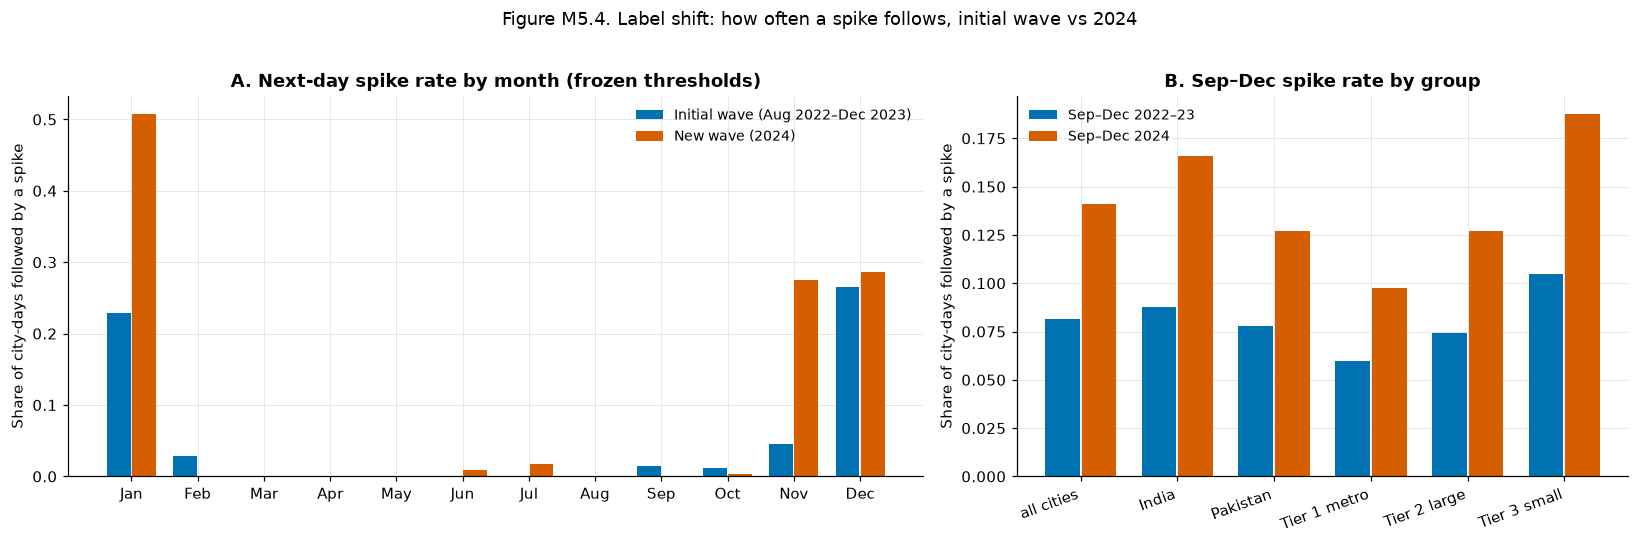

In [10]:
def rate_test(a, b):
    tab = np.array([[a.sum(), len(a) - a.sum()], [b.sum(), len(b) - b.sum()]])
    if tab[:, 0].sum() == 0:
        return np.nan
    return stats.chi2_contingency(tab, correction=False)[1] if tab.min() >= 5 else stats.fisher_exact(tab)[1]


trow = []
for period, (a_all, b_all) in COMPARE.items():
    for grouping, col in [("all", None), ("country", "country_name"), ("tier", "tier"), ("city", "city")]:
        gl = ["all cities"] if col is None else sorted(a_all[col].unique())
        for g in gl:
            a = a_all[TARGET] if col is None else a_all.loc[a_all[col] == g, TARGET]
            b = b_all[TARGET] if col is None else b_all.loc[b_all[col] == g, TARGET]
            trow.append({"period": period, "grouping": grouping, "group": g, "n_ref": len(a), "spikes_ref": int(a.sum()),
                         "rate_ref": a.mean(), "n_new": len(b), "spikes_new": int(b.sum()), "rate_new": b.mean(),
                         "rate_ratio": b.mean() / a.mean() if a.mean() > 0 else np.nan, "p_value": rate_test(a, b)})
for m in range(1, 13):
    a, b = init.loc[init.date.dt.month == m, TARGET], new.loc[new.date.dt.month == m, TARGET]
    trow.append({"period": "by month", "grouping": "month", "group": f"{m:02d}", "n_ref": len(a), "spikes_ref": int(a.sum()),
                 "rate_ref": a.mean(), "n_new": len(b), "spikes_new": int(b.sum()), "rate_new": b.mean(),
                 "rate_ratio": b.mean() / a.mean() if a.mean() > 0 else np.nan, "p_value": rate_test(a, b)})
target_shift = pd.DataFrame(trow)
_ = save_table(target_shift, "m5_target_shift", index=False)
print(target_shift[target_shift.grouping != "city"].round(4).to_string(index=False))

# Figure M5.4: spike rate by calendar month, and season-matched by group
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
mm = target_shift[target_shift.grouping == "month"]
x = np.arange(12)
for k, (w, col) in enumerate([("initial", "rate_ref"), ("new", "rate_new")]):
    axes[0].bar(x + (k - 0.5) * 0.38, mm[col], width=0.36, color=WAVE_COLOR[w], label=WAVE_LABEL[w])
axes[0].set_xticks(x); axes[0].set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
axes[0].set(ylabel="Share of city-days followed by a spike", title="A. Next-day spike rate by month (frozen thresholds)")
axes[0].legend(fontsize=9)
gs_ = target_shift[(target_shift.period == "season-matched (Sep-Dec)") & target_shift.grouping.isin(["all", "country", "tier"])]
xg = np.arange(len(gs_))
for k, (w, col) in enumerate([("initial", "rate_ref"), ("new", "rate_new")]):
    axes[1].bar(xg + (k - 0.5) * 0.38, gs_[col], width=0.36, color=WAVE_COLOR[w],
                label="Sep–Dec 2022–23" if w == "initial" else "Sep–Dec 2024")
axes[1].set_xticks(xg); axes[1].set_xticklabels([g.split(" (")[0] for g in gs_.group], rotation=20, ha="right")
axes[1].set(ylabel="Share of city-days followed by a spike", title="B. Sep–Dec spike rate by group")
axes[1].legend(fontsize=9)
fig.suptitle("Figure M5.4. Label shift: how often a spike follows, initial wave vs 2024", y=1.02)
fig.tight_layout()
P.save(fig, "fig_m05_4_label_shift")
plt.show()

In [11]:
# Concept-drift test: pooled logit with 2024 x predictor interactions
cs = df[df.date.dt.month.isin([9, 10, 11, 12, 1, 2]) & (df.rain_day == 0)].copy()
cs["fire_log1p"] = np.log1p(cs["fire_cnt_up45_r300_all"])
TERMS = ["persist_margin", "temp_mean_c", "stagnant", "rh_mean_pct", "temp_range_c", "vec_len_kmh", "fire_log1p"]
ref_cs = cs[cs.wave == "initial"]
for t in TERMS:
    if t != "stagnant":                   # continuous terms per 1 SD of the initial wave
        cs[t] = (cs[t] - ref_cs[t].mean()) / ref_cs[t].std()
cs["y"] = cs[TARGET]
cs["wave_new"] = (cs.wave == "new").astype(int)
CTRL = [c for c in ["month_02", "month_09", "month_10", "month_11", "month_12"]] + MD.CITY_DUMMIES
concept, concept_sum = DR.concept_lr_test(cs, TERMS, "wave_new", "city", controls=CTRL)
concept["or_new_wave"] = concept["or_reference_wave"] * concept["ratio_of_or_new_vs_ref"]
summary_rows = pd.DataFrame([{"term": f"JOINT: {k}", "value": v} for k, v in concept_sum.items()])
_ = save_table(concept, "m5_concept_test", index=False)
_ = save_table(summary_rows, "m5_concept_summary", index=False)
print(concept.round(4).to_string(index=False))
print()
print(pd.Series(concept_sum).round(4).to_string())

                                    term  or_reference_wave  or_ref_lo  or_ref_hi  ratio_of_or_new_vs_ref  ratio_lo  ratio_hi  p_interaction_cluster  or_new_wave
                          persist_margin            20.8050    11.9278    36.2889                  0.7538    0.3498    1.6245                 0.4707      15.6833
                             temp_mean_c             0.9827     0.7473     1.2924                  1.4151    0.9098    2.2010                 0.1234       1.3907
                                stagnant             1.5779     0.9590     2.5963                  0.4309    0.2545    0.7294                 0.0017       0.6799
                             rh_mean_pct             1.3166     1.1103     1.5611                  0.9873    0.6543    1.4896                 0.9513       1.2998
                            temp_range_c             1.2570     1.0553     1.4973                  0.8462    0.6009    1.1918                 0.3393       1.0637
                            

bin    n  mean_predicted  observed_rate                  setting  brier
ALL 1298          0.0564         0.0686 validation, Sep-Dec 2023 0.0370
ALL 1276          0.1018         0.1411  zero-shot, Sep-Dec 2024 0.0687
ALL 3960          0.0716         0.0914   zero-shot, all of 2024 0.0399

  month                    source   n  spikes  observed_rate  mean_predicted  pr_auc  recall   fpr
2022-09              training OOF 330      10          0.030           0.029   0.307   0.800 0.056
2022-10              training OOF 341       8          0.023           0.049   0.266   1.000 0.072
2022-11              training OOF 330      18          0.055           0.072   0.396   0.722 0.154
2022-12              training OOF 286      81          0.283           0.229   0.611   0.963 0.463
2023-01              training OOF 341      78          0.229           0.187   0.771   0.987 0.297
2023-02              training OOF 308       9          0.029           0.051   0.581   0.889 0.097
2023-11 validation

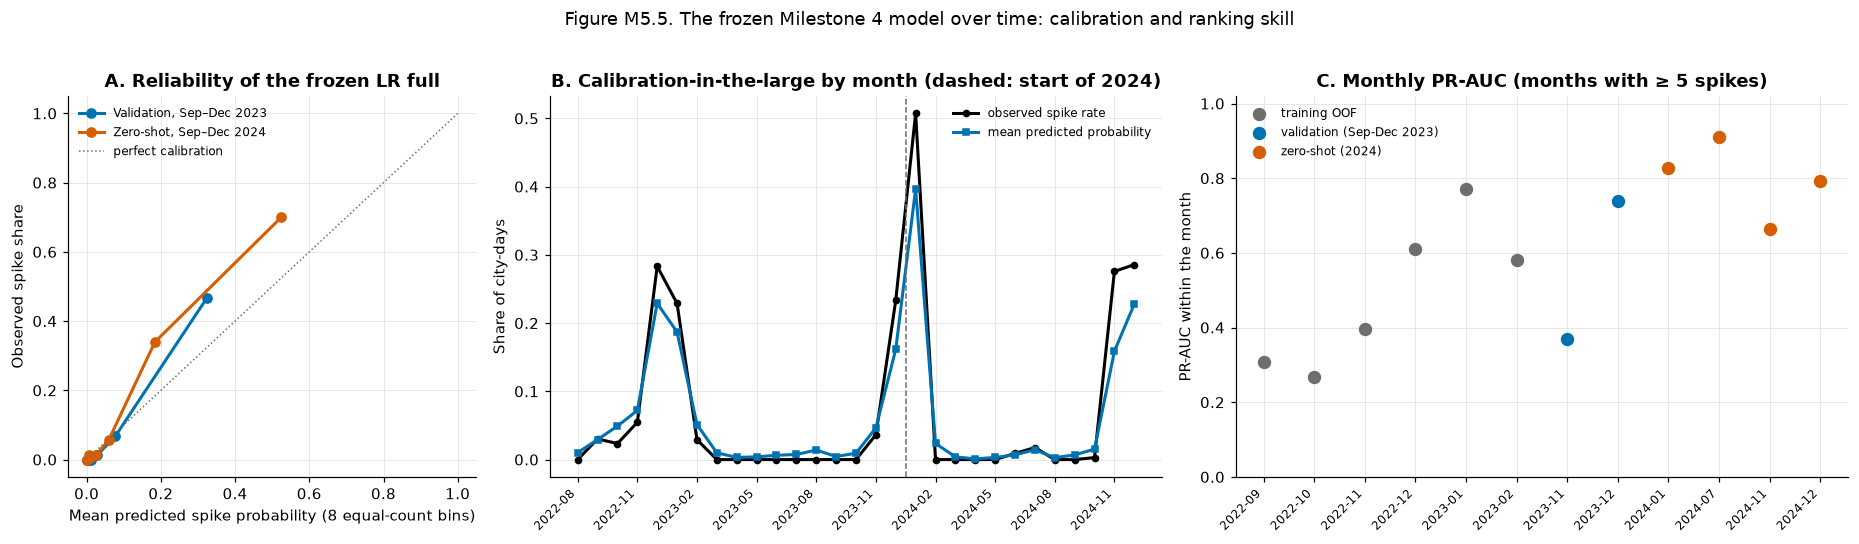

In [12]:
# Frozen Milestone 3-4 models: calibration over time (all predictions out of sample)
ZS = ["lr_full", "lr_no_fire", "lr_weather_only", "dt_full", "rf_full", "hgb_full"]
frozen_models = {m: joblib.load(f"models/{m}.joblib") for m in ZS + ["majority"]}
thr0 = {m: (m3["models"][m]["threshold"] if m in m3["models"] else m4["models"][m]["threshold"]) for m in ZS}
mit0 = m4["mitigation_thresholds"]["LR full"]
RULES0 = {"single threshold": {g: thr0["lr_full"] for g in FA.TIER_LABEL.values()},
          "threshold per tier": mit0["threshold per tier, cost-optimal"],
          f"equalized odds, ε = {EPS_HEADLINE}": mit0[f"equalized odds, ε = {EPS_HEADLINE}"]}
feat_of = lambda m: MD.FEATURE_SETS["full" if m == "majority" else m.split("_", 1)[1]]

# Out-of-fold predictions of the frozen LR full on its own (Milestone 3) training rows
splits4 = MD.purged_sgkf_splits(train4, train4[TARGET].to_numpy(), n_splits=5, seeds=SEEDS, horizon=H)
oof4, _ = MD.oof_predict(frozen_models["lr_full"], train4[feat_of("lr_full")], train4[TARGET].to_numpy(), splits4)
oos = pd.concat([
    train4[["city", "date", "tier", TARGET]].assign(p=oof4, source="training OOF"),
    val4[["city", "date", "tier", TARGET]].assign(p=frozen_models["lr_full"].predict_proba(val4[feat_of("lr_full")])[:, 1],
                                                   source="validation (Sep-Dec 2023)"),
    new[["city", "date", "tier", TARGET]].assign(p=frozen_models["lr_full"].predict_proba(new[feat_of("lr_full")])[:, 1],
                                                 source="zero-shot (2024)")], ignore_index=True)
oos["month"] = oos.date.dt.strftime("%Y-%m")
mrows = []
for (mo, src), g in oos.groupby(["month", "source"]):
    y, p = g[TARGET].to_numpy(), g.p.to_numpy()
    yh = (p >= thr0["lr_full"]).astype(int)
    mrows.append({"month": mo, "source": src, "n": len(g), "spikes": int(y.sum()), "observed_rate": y.mean(),
                  "mean_predicted": p.mean(), "pr_auc": average_precision_score(y, p) if 0 < y.sum() < len(y) else np.nan,
                  "recall": yh[y == 1].mean() if y.sum() > 0 else np.nan, "fpr": yh[y == 0].mean()})
monthly = pd.DataFrame(mrows)
_ = save_table(monthly, "m5_monthly_skill", index=False)

cal = []
for name, d in [("validation, Sep-Dec 2023", oos[oos.source == "validation (Sep-Dec 2023)"]),
                ("zero-shot, Sep-Dec 2024", oos[(oos.source == "zero-shot (2024)") & (oos.date >= C.M5_TEST_START)]),
                ("zero-shot, all of 2024", oos[oos.source == "zero-shot (2024)"])]:
    ct = DR.calibration_table(d[TARGET], d.p).assign(setting=name)
    cal.append(ct)
    cal.append(pd.DataFrame([{"bin": "ALL", "n": len(d), "mean_predicted": d.p.mean(), "observed_rate": d[TARGET].mean(),
                              "setting": name, "brier": float(np.mean((d.p - d[TARGET]) ** 2))}]))
calib = pd.concat(cal, ignore_index=True)
_ = save_table(calib, "m5_calibration", index=False)
print(calib[calib.bin == "ALL"].round(4).to_string(index=False))
print()
print(monthly[monthly.spikes >= 5].round(3).to_string(index=False))

# Figure M5.5: reliability, calibration-in-the-large by month, monthly PR-AUC
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1.5, 1.5]})
for (name, src, lo), col in zip([("Validation, Sep–Dec 2023", "validation (Sep-Dec 2023)", None),
                                 ("Zero-shot, Sep–Dec 2024", "zero-shot (2024)", C.M5_TEST_START)],
                                [P.CAT_COLORS[0], P.CAT_COLORS[1]]):
    d = oos[(oos.source == src) & ((oos.date >= lo) if lo else True)]
    frac, mean_p = calibration_curve(d[TARGET], d.p, n_bins=8, strategy="quantile")
    axes[0].plot(mean_p, frac, marker="o", color=col, lw=2, label=name)
axes[0].plot([0, 1], [0, 1], color=P.GREY, ls=":", lw=1, label="perfect calibration")
axes[0].set(xlabel="Mean predicted spike probability (8 equal-count bins)", ylabel="Observed spike share",
            title="A. Reliability of the frozen LR full")
axes[0].legend(fontsize=8)
mo = monthly.sort_values("month")
xm = np.arange(len(mo))
axes[1].plot(xm, mo.observed_rate, color="#000000", lw=2, marker="o", ms=4, label="observed spike rate")
axes[1].plot(xm, mo.mean_predicted, color=P.CAT_COLORS[0], lw=2, marker="s", ms=4, label="mean predicted probability")
axes[1].axvline(int(np.flatnonzero(mo.month.to_numpy() == "2024-01")[0]) - 0.5, color=P.GREY, ls="--", lw=1)
axes[1].set_xticks(xm[::3]); axes[1].set_xticklabels(mo.month.iloc[::3], rotation=45, ha="right", fontsize=8)
axes[1].set(ylabel="Share of city-days", title="B. Calibration-in-the-large by month (dashed: start of 2024)")
axes[1].legend(fontsize=8)
mp = mo[mo.spikes >= 5]
for src, col in [("training OOF", P.GREY), ("validation (Sep-Dec 2023)", P.CAT_COLORS[0]), ("zero-shot (2024)", P.CAT_COLORS[1])]:
    s = mp[mp.source == src]
    axes[2].scatter(s.month, s.pr_auc, s=60, color=col, label=src, zorder=3)
axes[2].set_xticks(range(len(mp))); axes[2].set_xticklabels(mp.month, rotation=45, ha="right", fontsize=8)
axes[2].set(ylim=(0, 1.02), ylabel="PR-AUC within the month", title="C. Monthly PR-AUC (months with ≥ 5 spikes)")
axes[2].legend(fontsize=8)
fig.suptitle("Figure M5.5. The frozen Milestone 4 model over time: calibration and ranking skill", y=1.02)
fig.tight_layout()
P.save(fig, "fig_m05_5_calibration_time")
plt.show()

**What we found (M5.5)**

- **The label shifted most.** With frozen thresholds, the next-day spike rate rose from 5.4% to 9.1% overall and from 8.1% to 14.1% in Sep–Dec.
- **November changed the most.** Its spike rate rose from 4.5% to 27.6% of city-days. January rose from 22.9% to 50.7%.
- **Every tier and most cities saw more spikes.** Lahore is the exception: 2 spikes in 2024 against 18 before. Its frozen threshold (2.18) is the highest of the 11 cities.
- **The relation between predictors and spikes changed (concept drift).** The 2024 interactions improve the pooled logit: LR χ² 22.7 on 7 df, p 0.002, with city-cluster Wald p < 0.001.
- **Two effects changed.** The stagnation effect weakened (ratio of odds ratios 0.43 [0.25, 0.73]). The upwind-fire effect strengthened (1.51 [1.21, 1.88]). The 2024 intercept ratio is 2.78 [1.10, 7.03].
- **The frozen LR under-predicts 2024.** For Sep–Dec 2024 it predicts a mean probability of 0.102 against an observed rate of 0.141. The Brier score rose from 0.037 to 0.069.

---
## M5.6 Zero-shot test of the Milestone 4 models

- **Setup:** the saved models (`models/*.joblib`) and their saved thresholds are applied to 2024 without any refit. The thresholds are 5:1 cost-optimal on the Milestone 3–4 out-of-fold predictions. LR full also gets the per-tier thresholds and the equalized-odds thresholds from `m4_params.json`.
- **Settings:**
  - **(1)** initial model on initial data: the Milestone 4 validation season, Sep–Dec 2023, recomputed and checked against the Milestone 4 tables;
  - **(2a)** initial model on all of 2024;
  - **(2b)** initial model on Sep–Dec 2024, the same season as (1) and the test season of the re-trained models.
- **Uncertainty:** 95% CIs come from resampling whole calendar weeks (1,000 draws).

In [13]:
METRICS = ["accuracy", "precision", "recall", "specificity", "f1", "roc_auc", "pr_auc", "brier", "cost_per_1000"]
BASE_COLS = ["city", "country", "country_name", "tier", "date", "persist_spike", TARGET, "target_index_h1",
             "fire_gap_affected"]


def score_frozen(fr):
    # Scores and alerts of every frozen model on a frame; nothing is refitted
    out = fr[[c for c in BASE_COLS if c in fr.columns]].copy()
    out["s_persistence"], out["p_persistence"] = MD.persistence(fr)
    out["s_majority"] = frozen_models["majority"].predict_proba(fr[feat_of("majority")])[:, 1]
    out["p_majority"] = 0
    for m in ZS:
        out[f"s_{m}"] = frozen_models[m].predict_proba(fr[feat_of(m)])[:, 1]
        out[f"p_{m}"] = (out[f"s_{m}"] >= thr0[m]).astype(int)
    for name, thr in RULES0.items():
        out[f"p_lr_full|{name}"] = FA.apply_thresholds(out["s_lr_full"], out["tier"], thr)
    return out


ZS_MODELS = ["majority", "persistence"] + ZS
SETTINGS0 = {"(1) initial model, initial data (Sep-Dec 2023)": score_frozen(val4),
             "(2a) initial model, zero-shot, all of 2024": score_frozen(new),
             "(2b) initial model, zero-shot, Sep-Dec 2024": score_frozen(test)}


def metrics_fn(models, prefix_s="s_", prefix_p="p_"):
    def fn(d):
        out = {}
        for m in models:
            r = EV.binary_metrics(d[TARGET], d[f"{prefix_s}{m}"], yhat=d[f"{prefix_p}{m}"])
            out.update({f"{m}|{k}": r[k] for k in METRICS})
        return out
    return fn


zs_rows, zs_counts = [], []
for setting, fr in SETTINGS0.items():
    bb = EV.block_bootstrap(fr, metrics_fn(ZS_MODELS), n=N_BOOT, seed=42)
    for idx, r in bb.iterrows():
        m, k = idx.split("|")
        zs_rows.append({"setting": setting, "model": LABEL[m], "metric": k, "estimate": r.estimate,
                        "ci_low": r.ci_low, "ci_high": r.ci_high, "n_weeks": r.n_weeks})
    for m in ZS_MODELS + [f"lr_full|{n}" for n in RULES0]:
        pc = f"p_{m}"
        sc = "s_lr_full" if "|" in m else f"s_{m}"
        r = EV.binary_metrics(fr[TARGET], fr[sc], yhat=fr[pc])
        zs_counts.append({"setting": setting, "model": LABEL.get(m, "LR full, " + m.split("|")[-1]),
                          **{k: r[k] for k in ["tp", "fp", "tn", "fn", "n"] + METRICS}})
zeroshot = pd.DataFrame(zs_rows)
zs_counts = pd.DataFrame(zs_counts)
_ = save_table(zeroshot, "m5_zeroshot", index=False)
_ = save_table(zs_counts, "m5_zeroshot_counts", index=False)

# Setting (1) must reproduce Milestone 4
m4_val = pd.read_csv("docs/tables/m4_metrics_validation.csv")
m4_mit = pd.read_csv("docs/tables/m4_mitigation.csv")
s1 = zs_counts[zs_counts.setting.str.startswith("(1)")].set_index("model")
for m in ["LR full", "DT full", "RF full", "HGB full", "Persistence"]:
    for k in ["pr_auc", "cost_per_1000"]:
        old = m4_val[(m4_val.model == m) & (m4_val.metric == k)]["estimate"].iloc[0]
        assert abs(old - s1.loc[m, k]) < 1e-3, f"{m} {k}: {s1.loc[m, k]} vs Milestone 4 {old}"
old_tier = m4_mit[(m4_mit.model == "LR full") & (m4_mit.method == "threshold per tier, cost-optimal")
                  & (m4_mit.data == "validation")]["cost_per_1000"].iloc[0]
assert abs(old_tier - s1.loc["LR full, threshold per tier", "cost_per_1000"]) < 1e-3
print("Setting (1) reproduces the Milestone 4 validation tables.\n")
show = zs_counts[zs_counts.model.isin(["Persistence", "LR full", "LR full, threshold per tier", "DT full", "RF full", "HGB full"])]
print(show[["setting", "model", "tp", "fp", "fn", "recall", "precision", "f1", "roc_auc", "pr_auc", "brier",
            "cost_per_1000"]].round(4).to_string(index=False))

Setting (1) reproduces the Milestone 4 validation tables.

                                       setting                       model  tp  fp  fn  recall  precision     f1  roc_auc  pr_auc  brier  cost_per_1000
(1) initial model, initial data (Sep-Dec 2023)                 Persistence  55  25  34  0.6180     0.6875 0.6509   0.9629  0.6687    NaN       150.2311
(1) initial model, initial data (Sep-Dec 2023)                     LR full  77  92  12  0.8652     0.4556 0.5969   0.9665  0.6946 0.0370       117.1032
(1) initial model, initial data (Sep-Dec 2023)                     DT full  73  67  16  0.8202     0.5214 0.6376   0.9531  0.5895 0.0371       113.2512
(1) initial model, initial data (Sep-Dec 2023)                     RF full  73  69  16  0.8202     0.5141 0.6320   0.9639  0.6794 0.0353       114.7920
(1) initial model, initial data (Sep-Dec 2023)                    HGB full  76  78  13  0.8539     0.4935 0.6255   0.9628  0.6360 0.0627       110.1695
(1) initial model, initial da

**What we found (M5.6)**

- **Zero-shot ranking skill held.** On all of 2024 the frozen LR full reaches PR-AUC 0.768 (ROC-AUC 0.973). On Sep–Dec 2024 it reaches 0.726 [0.565, 0.798], against 0.695 on its own validation season.
- **Precision and F1 rose with the higher spike rate.** For Sep–Dec, precision went from 0.456 to 0.584 and F1 from 0.597 to 0.705.
- **The cost of errors grew** from 117.1 to 167.7 per 1,000 city-days on Sep–Dec.
- **The model still beats persistence on cost.** Persistence costs 243.7. The paired difference LR − persistence is −76.0 [−161.7, −0.8] per 1,000 city-days.

---
## M5.7 Re-training on the combined data

- **Training rows:** 2022-08-04 → 2024-08-31. That is the whole initial wave, including the Milestone 4 validation season, plus Jan–Aug 2024.
- **CV:** the same purged, repeated StratifiedGroupKFold as Milestones 3–4 (5 folds × 5 repeats, calendar-week groups, 1-day purge and 3-day embargo).
- **Searches:**
  - **Baselines:** majority class, persistence, and LR and DT on the 3 feature sets with the Milestone 3 grids.
  - **Advanced:** RF and HGB on the full and no-fire sets with the Milestone 4 random-search spaces (60 draws each). The weather-only ensembles are left out to save run time. LR and DT already cover the weather-only ablation.
- **Thresholds and final model:** the 5:1 thresholds, per-tier thresholds and equalized-odds thresholds come from the out-of-fold predictions of the training rows. The Milestone 4 final-model rule is applied again: highest CV PR-AUC among the full-feature models; within 0.005 counts as a tie, and the simplest tied model wins.

In [14]:
y_tr, y_te = train[TARGET].to_numpy(), test[TARGET].to_numpy()
assert_train_only(train)
assert test["date"].min() >= pd.Timestamp(C.M5_TEST_START)
splits = MD.purged_sgkf_splits(train, y_tr, n_splits=5, seeds=SEEDS, horizon=H)
X_tr = {s: train[MD.FEATURE_SETS[s]] for s in SETS}
X_te = {s: test[MD.FEATURE_SETS[s]] for s in SETS}
RT_MODELS = (["majority", "persistence"] + [f"{f}_{s}" for f in ["lr", "dt"] for s in SETS]
             + [f"{f}_{s}" for f in ["rf", "hgb"] for s in ["full", "no_fire"]])

searches, tuning = {}, {f: [] for f in FAM_LABEL}
for fam, make, space, kind in [("lr", MD.make_lr, MD.LR_GRID, "grid"), ("dt", MD.make_tree, MD.DT_GRID, "grid"),
                               ("rf", MD.make_rf, MD.RF_DIST, "random"), ("hgb", MD.make_hgb, MD.HGB_DIST, "random")]:
    for s in (SETS if kind == "grid" else ["full", "no_fire"]):
        t = time.time()
        assert_train_only(train)
        if kind == "grid":
            sr = MD.tune(make(MD.FEATURE_SETS[s]), space, X_tr[s], y_tr, splits)
        else:
            sr = MD.tune_random(make(MD.FEATURE_SETS[s]), space, X_tr[s], y_tr, splits, n_iter=N_ITER, seed=42)
        searches[f"{fam}_{s}"] = sr
        res = pd.DataFrame(sr.cv_results_["params"])
        res.columns = [c.replace("model__", "") for c in res.columns]
        res = res.astype(object).where(res.notna(), "none")
        res = res.assign(feature_set=s, cv_pr_auc_mean=sr.cv_results_["mean_test_score"],
                         cv_pr_auc_sd=sr.cv_results_["std_test_score"], rank=sr.cv_results_["rank_test_score"])
        tuning[fam].append(res)
        print(f"{LABEL[f'{fam}_{s}']:<18} best CV PR-AUC {sr.best_score_:.4f}  "
              f"{ {k.replace('model__', ''): (round(float(v), 4) if isinstance(v, float) else v) for k, v in sr.best_params_.items()} }"
              f"  ({time.time() - t:.0f} s)")
for fam in FAM_LABEL:
    _ = save_table(pd.concat(tuning[fam]), f"m5_tuning_{fam}", index=False)

rt_fitted, rt_oof, rt_folds, rt_thr, rt_cv = {}, {}, {}, {}, {}
rt_fitted["majority"] = MD.make_majority().fit(X_tr["full"], y_tr)
rt_oof["majority"], rt_folds["majority"] = MD.oof_predict(MD.make_majority(), X_tr["full"], y_tr, splits)
for m, sr in searches.items():
    rt_fitted[m] = sr.best_estimator_
    rt_oof[m], rt_folds[m] = MD.oof_predict(sr.best_estimator_, X_tr[m.split("_", 1)[1]], y_tr, splits)
    rt_cv[m] = float(sr.best_score_)
for m in rt_oof:
    rt_thr[m], _ = MD.choose_threshold(y_tr, rt_oof[m], COST_FN, COST_FP)
pers_tr = MD.persistence(train)

cands = ["lr_full", "dt_full", "rf_full", "hgb_full"]
best = max(rt_cv[m] for m in cands)
FINAL_RT = next(m for m in cands if rt_cv[m] >= best - 0.005)
BEST_ADV_RT = max(["rf_full", "hgb_full"], key=lambda m: rt_cv[m])
tier_tr, tier_te = train["tier"].to_numpy(), test["tier"].to_numpy()
RULES_RT = {"single threshold": {g: rt_thr[FINAL_RT] for g in FA.TIER_LABEL.values()},
            "threshold per tier": FA.group_thresholds(y_tr, rt_oof[FINAL_RT], tier_tr, COST_FN, COST_FP),
            f"equalized odds, ε = {EPS_HEADLINE}": FA.constrained_thresholds(
                y_tr, rt_oof[FINAL_RT], tier_tr, EPS_HEADLINE, "eo", COST_FN, COST_FP)[0]}
assert all(v is not None for v in RULES_RT.values())

summ = []
for m in RT_MODELS[2:]:
    before = m3["models"].get(m, m4["models"].get(m, {}))
    summ.append({"model": LABEL[m], "best_params_retrained": json.dumps({k.replace("model__", ""): (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v))
                                                                         for k, v in searches[m].best_params_.items()}),
                 "cv_pr_auc_retrained": rt_cv[m], "cv_pr_auc_initial": before.get("cv_pr_auc", np.nan),
                 "threshold_retrained": rt_thr[m], "threshold_initial": before.get("threshold", np.nan)})
retrain_summary = pd.DataFrame(summ)
_ = save_table(retrain_summary, "m5_retrain_summary", index=False)
print()
print(retrain_summary.round(4).to_string(index=False))
print(f"\nFinal re-trained model: {LABEL[FINAL_RT]}; best ensemble: {LABEL[BEST_ADV_RT]}")
print("Re-trained thresholds for", LABEL[FINAL_RT], {k: {g.split(' (')[0]: round(v, 4) for g, v in thr.items()} for k, thr in RULES_RT.items()})
print(f"Training rows {len(train):,} ({int(y_tr.sum())} spikes); folds {len(splits)}")

LR full            best CV PR-AUC 0.7383  {'C': 0.0052, 'class_weight': None, 'l1_ratio': 1.0}  (23 s)


LR weather-only    best CV PR-AUC 0.5094  {'C': 3.7276, 'class_weight': None, 'l1_ratio': 0.0}  (14 s)


LR no-fire         best CV PR-AUC 0.7383  {'C': 0.0052, 'class_weight': None, 'l1_ratio': 1.0}  (17 s)


DT full            best CV PR-AUC 0.6573  {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 50}  (25 s)


DT weather-only    best CV PR-AUC 0.3965  {'class_weight': 'balanced', 'max_depth': 8, 'min_samples_leaf': 25}  (14 s)


DT no-fire         best CV PR-AUC 0.6665  {'class_weight': None, 'max_depth': 5, 'min_samples_leaf': 50}  (16 s)


RF full            best CV PR-AUC 0.7100  {'n_estimators': 500, 'min_samples_leaf': 100, 'max_features': 1.0, 'max_depth': 5, 'class_weight': 'balanced'}  (1453 s)


RF no-fire         best CV PR-AUC 0.7133  {'n_estimators': 300, 'min_samples_leaf': 5, 'max_features': 1.0, 'max_depth': 3, 'class_weight': None}  (1259 s)


HGB full           best CV PR-AUC 0.7013  {'class_weight': 'balanced', 'l2_regularization': 0.0572, 'learning_rate': 0.0199, 'max_depth': 8, 'max_iter': 330, 'max_leaf_nodes': 7, 'min_samples_leaf': 61}  (677 s)


HGB no-fire        best CV PR-AUC 0.7030  {'class_weight': 'balanced', 'l2_regularization': 0.0572, 'learning_rate': 0.0199, 'max_depth': 8, 'max_iter': 330, 'max_leaf_nodes': 7, 'min_samples_leaf': 61}  (565 s)



          model                                                                                                                                            best_params_retrained  cv_pr_auc_retrained  cv_pr_auc_initial  threshold_retrained  threshold_initial
        LR full                                                                                                             {"C": 0.0052, "class_weight": null, "l1_ratio": 1.0}               0.7383             0.6508               0.1738             0.1280
LR weather-only                                                                                                             {"C": 3.7276, "class_weight": null, "l1_ratio": 0.0}               0.5094             0.4319               0.1944             0.1009
     LR no-fire                                                                                                             {"C": 0.0052, "class_weight": null, "l1_ratio": 1.0}               0.7383             0.6507            

**What we found (M5.7)**

- **More winters raise the CV PR-AUC of every model.** LR full rises from 0.651 to 0.738, RF from 0.590 to 0.710, HGB from 0.565 to 0.701 and DT from 0.519 to 0.657.
- **The fixed rule again chooses LR full.** The selected setting is C = 0.0052 with an L1 penalty. Its 5:1 threshold moves from 0.128 to 0.174.
- **RF full is the best ensemble.**
- **Fires still add nothing to LR.** LR full and LR no-fire reach the same CV PR-AUC (0.738), because the L1 penalty keeps only two columns: today's index margin and mean temperature. Milestone 4 kept the same two.

---
## M5.8 Three-way comparison

- **Settings:** the brief's three settings, plus the literal reading of setting 3:
  - **(1)** initial model on initial data (Sep–Dec 2023);
  - **(2b)** initial model on the new wave (zero-shot), with **(2a)** all of 2024 for reference;
  - **(3a)** re-trained model on the held-out Sep–Dec 2024 season;
  - **(3b)** re-trained model on the combined dataset, as purged 25-fold CV over all 2022-08 → 2024-12 rows. Its thresholds stay the ones chosen on the training rows.
- **Comparison:** (2b) and (3a) score the same rows, so their difference is paired. Its CI comes from resampling the same weeks for both.

In [15]:
# (3a) re-trained models on the test season
te = test[[c for c in BASE_COLS]].copy()
te["s_persistence"], te["p_persistence"] = MD.persistence(test)
for m in RT_MODELS:
    if m == "persistence":
        continue
    te[f"s_{m}"] = rt_fitted[m].predict_proba(X_te["full" if m == "majority" else m.split("_", 1)[1]])[:, 1]
    te[f"p_{m}"] = 0 if m == "majority" else (te[f"s_{m}"] >= rt_thr[m]).astype(int)
for name, thr in RULES_RT.items():
    te[f"p_{FINAL_RT}|{name}"] = FA.apply_thresholds(te[f"s_{FINAL_RT}"], te["tier"], thr)
zs_te = SETTINGS0["(2b) initial model, zero-shot, Sep-Dec 2024"]
for m in ZS + ["persistence"]:
    te[f"s_zs_{m}"], te[f"p_zs_{m}"] = zs_te[f"s_{m}"].to_numpy(), zs_te[f"p_{m}"].to_numpy()

rows3, counts3 = [], []
bb = EV.block_bootstrap(te, metrics_fn(RT_MODELS), n=N_BOOT, seed=42)
for idx, r in bb.iterrows():
    m, k = idx.split("|")
    rows3.append({"setting": "(3a) re-trained model, Sep-Dec 2024 test", "model": LABEL[m], "metric": k,
                  "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high, "sd": np.nan})
for m in RT_MODELS + [f"{FINAL_RT}|{n}" for n in RULES_RT]:
    sc = f"s_{m.split('|')[0]}"
    r = EV.binary_metrics(te[TARGET], te[sc], yhat=te[f"p_{m}"])
    counts3.append({"setting": "(3a) re-trained model, Sep-Dec 2024 test",
                    "model": LABEL.get(m, f"{LABEL[FINAL_RT]}, " + m.split("|")[-1]),
                    **{k: r[k] for k in ["tp", "fp", "tn", "fn", "n"] + METRICS}})

# (3b) re-trained models, purged CV over the combined dataset (all rows, train + test season)
y_all = df[TARGET].to_numpy()
splits_all = MD.purged_sgkf_splits(df, y_all, n_splits=5, seeds=SEEDS, horizon=H)
p_all = MD.persistence(df)
cv3b = {"persistence": EV.cv_metrics(y_all, [(t, p_all[0][t]) for _, t in splits_all], yhat=p_all[1])}
for m in ["lr_full", "lr_no_fire", "dt_full", "rf_full", "hgb_full"]:
    _, folds = MD.oof_predict(clone(rt_fitted[m]), df[MD.FEATURE_SETS[m.split("_", 1)[1]]], y_all, splits_all)
    cv3b[m] = EV.cv_metrics(y_all, folds, threshold=rt_thr[m])
for m, r in cv3b.items():
    for k in METRICS:
        rows3.append({"setting": "(3b) re-trained model, combined data, purged CV", "model": LABEL[m], "metric": k,
                      "estimate": r[f"{k}_mean"], "ci_low": np.nan, "ci_high": np.nan, "sd": r[f"{k}_sd"]})
three = pd.concat([zeroshot.assign(sd=np.nan).drop(columns="n_weeks"), pd.DataFrame(rows3)], ignore_index=True)
_ = save_table(three, "m5_three_way", index=False)
counts_all = pd.concat([zs_counts, pd.DataFrame(counts3)], ignore_index=True)
_ = save_table(counts_all, "m5_three_way_counts", index=False)

# Compact wide table for the report
SHOW_M = ["Persistence", "LR full", "DT full", "RF full", "HGB full"]
order_s = ["(1) initial model, initial data (Sep-Dec 2023)", "(2a) initial model, zero-shot, all of 2024",
           "(2b) initial model, zero-shot, Sep-Dec 2024", "(3a) re-trained model, Sep-Dec 2024 test",
           "(3b) re-trained model, combined data, purged CV"]
wide = (three[three.model.isin(SHOW_M)].pivot_table(index=["setting", "model"], columns="metric", values="estimate")
        .reindex(columns=METRICS))
wide = wide.reindex([(s, m) for s in order_s for m in SHOW_M if (s, m) in wide.index])
_ = save_table(wide, "m5_three_way_wide")
print(wide.round(3).to_string())

metric                                                       accuracy  precision  recall  specificity     f1  roc_auc  pr_auc  brier  cost_per_1000
setting                                         model                                                                                              
(1) initial model, initial data (Sep-Dec 2023)  Persistence     0.955      0.688   0.618        0.979  0.651    0.963   0.669    NaN        150.231
                                                LR full         0.920      0.456   0.865        0.924  0.597    0.966   0.695  0.037        117.103
                                                DT full         0.936      0.521   0.820        0.945  0.638    0.953   0.590  0.037        113.251
                                                RF full         0.935      0.514   0.820        0.943  0.632    0.964   0.679  0.035        114.792
                                                HGB full        0.930      0.494   0.854        0.935  0.626    

In [16]:
# Paired differences on the Sep-Dec 2024 test rows (same weeks resampled for both models)
def pair_diff(d, a, b):
    if d[TARGET].nunique() < 2:
        return {"d_pr_auc": np.nan, "d_roc_auc": np.nan, "d_cost": np.nan, "d_recall": np.nan}
    ra = EV.binary_metrics(d[TARGET], d[f"s_{a}"], yhat=d[f"p_{a}"])
    rb = EV.binary_metrics(d[TARGET], d[f"s_{b}"], yhat=d[f"p_{b}"])
    return {"d_pr_auc": ra["pr_auc"] - rb["pr_auc"], "d_roc_auc": ra["roc_auc"] - rb["roc_auc"],
            "d_cost": ra["cost_per_1000"] - rb["cost_per_1000"], "d_recall": ra["recall"] - rb["recall"]}


LAB = lambda m: (LABEL[m[3:]] + " (zero-shot)") if m.startswith("zs_") else (LABEL[m] + (" (re-trained)" if m != "persistence" else ""))
PAIRS = [("lr_full", "zs_lr_full"), ("dt_full", "zs_dt_full"), ("rf_full", "zs_rf_full"), ("hgb_full", "zs_hgb_full"),
         ("lr_full", "persistence"), ("zs_lr_full", "persistence"), ("rf_full", "lr_full"), ("hgb_full", "lr_full"),
         ("lr_full", "lr_no_fire"), ("dt_full", "dt_no_fire"), ("rf_full", "rf_no_fire"), ("hgb_full", "hgb_no_fire"),
         ("lr_no_fire", "lr_weather_only"), ("zs_lr_full", "zs_lr_no_fire")]
pers_folds = [(t, pers_tr[0][t]) for _, t in splits]
rows = []
for a, b in PAIRS:
    bbp = EV.block_bootstrap(te, lambda d: pair_diff(d, a, b), n=N_BOOT, seed=42)
    fa = rt_folds.get(a, pers_folds) if not a.startswith("zs_") else None
    fb = rt_folds.get(b, pers_folds) if not b.startswith("zs_") else None
    if fa is not None and fb is not None:
        cv_d = np.array([average_precision_score(y_tr[t], pa) - average_precision_score(y_tr[t], pb)
                         for (t, pa), (_, pb) in zip(fa, fb)])
    else:
        cv_d = None
    for metric in ["pr_auc", "roc_auc", "cost", "recall"]:
        r = bbp.loc[f"d_{metric}"]
        rows.append({"comparison": f"{LAB(a)} − {LAB(b)}", "metric": metric, "test_diff": r.estimate,
                     "ci_low": r.ci_low, "ci_high": r.ci_high, "ci_excludes_0": bool(r.ci_low > 0 or r.ci_high < 0),
                     "cv_diff_mean": cv_d.mean() if (cv_d is not None and metric == "pr_auc") else np.nan,
                     "cv_folds_a_better": int((cv_d > 0).sum()) if (cv_d is not None and metric == "pr_auc") else np.nan})
deltas = pd.DataFrame(rows)
_ = save_table(deltas, "m5_deltas", index=False)
print(deltas.round(4).to_string(index=False))

# Generalization decay of the frozen model: (2b) - (1), unpaired (different rows)
dec = three[three.setting.isin([order_s[0], order_s[2], order_s[3]]) & three.model.isin(SHOW_M)
            & three.metric.isin(["pr_auc", "roc_auc", "recall", "precision", "f1", "brier", "cost_per_1000"])]
decay = dec.pivot_table(index=["model", "metric"], columns="setting", values="estimate").reindex(columns=[order_s[0], order_s[2], order_s[3]])
decay.columns = ["initial_valid_2023", "zero_shot_2024", "retrained_2024"]
decay["decay_zero_shot_minus_initial"] = decay["zero_shot_2024"] - decay["initial_valid_2023"]
decay["recovery_retrained_minus_zero_shot"] = decay["retrained_2024"] - decay["zero_shot_2024"]
_ = save_table(decay, "m5_decay")
print()
print(decay.round(4).to_string())

# Sensitivity: drop test rows whose fire features read a VIIRS gap day
gs_rows = []
for subset, mask in [("all test rows", np.ones(len(te), bool)), ("without fire-gap rows", te.fire_gap_affected.to_numpy() == 0)]:
    d = te[mask]
    for m in ["persistence", "zs_lr_full", "zs_rf_full", "zs_hgb_full", "lr_full", "rf_full", "hgb_full"]:
        r = EV.binary_metrics(d[TARGET], d[f"s_{m}"], yhat=d[f"p_{m}"])
        gs_rows.append({"subset": subset, "model": LAB(m), "n": r["n"], "spikes": int(d[TARGET].sum()),
                        **{k: r[k] for k in ["pr_auc", "roc_auc", "recall", "precision", "cost_per_1000"]}})
gap_sens = pd.DataFrame(gs_rows)
_ = save_table(gap_sens, "m5_fire_gap_sensitivity", index=False)
print()
print(gap_sens.round(4).to_string(index=False))

                                            comparison  metric  test_diff    ci_low  ci_high  ci_excludes_0  cv_diff_mean  cv_folds_a_better
            LR full (re-trained) − LR full (zero-shot)  pr_auc     0.0019   -0.0022   0.0070          False           NaN                NaN
            LR full (re-trained) − LR full (zero-shot) roc_auc     0.0005   -0.0006   0.0017          False           NaN                NaN
            LR full (re-trained) − LR full (zero-shot)    cost    -0.7837  -12.3267  11.5749          False           NaN                NaN
            LR full (re-trained) − LR full (zero-shot)  recall    -0.0111   -0.0172   0.0000          False           NaN                NaN
            DT full (re-trained) − DT full (zero-shot)  pr_auc     0.0169   -0.0281   0.0562          False           NaN                NaN
            DT full (re-trained) − DT full (zero-shot) roc_auc     0.0027   -0.0050   0.0069          False           NaN                NaN
            D

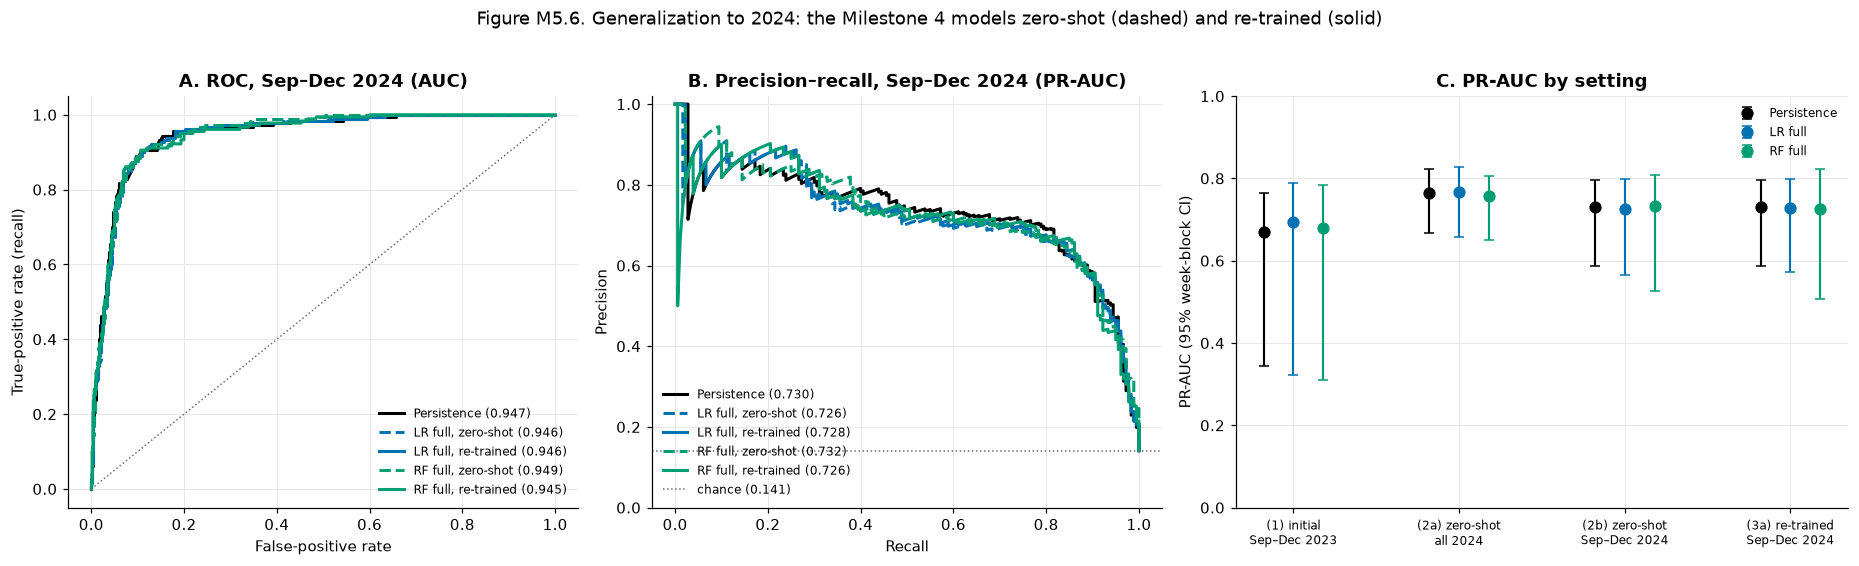

In [17]:
# Figure M5.6: ROC and PR on the Sep-Dec 2024 test season, zero-shot vs re-trained; PR-AUC by setting
fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1, 1, 1.2]})
curves = [("persistence", "Persistence", "#000000", "-"), ("zs_lr_full", "LR full, zero-shot", P.CAT_COLORS[0], "--"),
          ("lr_full", "LR full, re-trained", P.CAT_COLORS[0], "-"), ("zs_rf_full", "RF full, zero-shot", P.CAT_COLORS[2], "--"),
          ("rf_full", "RF full, re-trained", P.CAT_COLORS[2], "-")]
for m, lab, col, ls in curves:
    fpr, tpr, _ = roc_curve(te[TARGET], te[f"s_{m}"])
    prec, rec, _ = precision_recall_curve(te[TARGET], te[f"s_{m}"])
    axes[0].plot(fpr, tpr, color=col, ls=ls, lw=2, label=f"{lab} ({roc_auc_score(te[TARGET], te[f's_{m}']):.3f})")
    axes[1].plot(rec, prec, color=col, ls=ls, lw=2, label=f"{lab} ({average_precision_score(te[TARGET], te[f's_{m}']):.3f})")
axes[0].plot([0, 1], [0, 1], color=P.GREY, ls=":", lw=1)
axes[1].axhline(te[TARGET].mean(), color=P.GREY, ls=":", lw=1, label=f"chance ({te[TARGET].mean():.3f})")
axes[0].set(xlabel="False-positive rate", ylabel="True-positive rate (recall)", title="A. ROC, Sep–Dec 2024 (AUC)")
axes[1].set(xlabel="Recall", ylabel="Precision", title="B. Precision–recall, Sep–Dec 2024 (PR-AUC)", ylim=(0, 1.02))
axes[0].legend(fontsize=8, loc="lower right"); axes[1].legend(fontsize=8, loc="lower left")
sel = three[(three.metric == "pr_auc") & three.model.isin(["Persistence", "LR full", "RF full"])
            & three.setting.isin(order_s[:4])]
short = {order_s[0]: "(1) initial\nSep–Dec 2023", order_s[1]: "(2a) zero-shot\nall 2024",
         order_s[2]: "(2b) zero-shot\nSep–Dec 2024", order_s[3]: "(3a) re-trained\nSep–Dec 2024"}
for k, (m, col) in enumerate([("Persistence", "#000000"), ("LR full", P.CAT_COLORS[0]), ("RF full", P.CAT_COLORS[2])]):
    s = sel[sel.model == m].set_index("setting").loc[order_s[:4]]
    xv = np.arange(4) + (k - 1) * 0.18
    axes[2].errorbar(xv, s.estimate, yerr=[s.estimate - s.ci_low, s.ci_high - s.estimate], fmt="o", color=col,
                     ms=7, capsize=3, lw=1.4, label=m)
axes[2].set_xticks(range(4)); axes[2].set_xticklabels([short[s] for s in order_s[:4]], fontsize=8)
axes[2].set(ylabel="PR-AUC (95% week-block CI)", title="C. PR-AUC by setting", ylim=(0, 1))
axes[2].legend(fontsize=8)
fig.suptitle("Figure M5.6. Generalization to 2024: the Milestone 4 models zero-shot (dashed) and re-trained (solid)", y=1.02)
fig.tight_layout()
P.save(fig, "fig_m05_6_roc_pr")
plt.show()

**What we found (M5.8)**

- **Re-training did not raise the final model's ranking skill.** On the Sep–Dec 2024 test, re-trained LR full scores PR-AUC 0.728 and cost 166.9. The paired re-trained − zero-shot difference is 0.002 [−0.002, 0.007] in PR-AUC.
- **HGB gained, RF did not.** For HGB the gain is 0.048 [0.003, 0.090], the only interval that excludes 0. It brings HGB level with LR. For RF the change is −0.006 [−0.047, 0.033].
- **The ensembles still do not beat LR.** Re-trained, RF − LR is −0.001 [−0.090, 0.035] and HGB − LR 0.001 [−0.040, 0.022].
- **On the combined data (3b)**, the purged CV gives LR full PR-AUC 0.727 and cost 95.7 per 1,000 city-days.
- **The fire-gap days do not drive the result.** Dropping the 110 test rows that read a VIIRS gap day moves the re-trained LR PR-AUC from 0.728 to 0.730.

---
## M5.9 Fairness shift and population exposure

- **Metrics:** the same group metrics as Milestone 4, by country (privileged: Pakistan) and city-size tier (privileged: Tier 1 metros):
  - disparate impact ratio (DIR, two-sided 80% rule: 0.8–1.25);
  - demographic-parity difference;
  - equal-opportunity gap (TPR);
  - predictive-equality gap (FPR);
  - equalized-odds gap.
- **Settings:**
  - (1) Milestone 4 validation;
  - (2a) all of 2024 and (2b) Sep–Dec 2024, both zero-shot with the frozen thresholds;
  - (3a) re-trained, with thresholds re-chosen on the new out-of-fold predictions.
- **Threshold rules:** single 5:1 threshold, per-tier cost-optimal thresholds, and equalized-odds thresholds at ε = 0.05.
- **Question:** did adding 2024 reduce or widen the gaps? On the shared test rows, re-trained − zero-shot is a paired difference with a week-block CI.
- **Exposure (lite Extension 2):** person-days exposed = census population × spike days. Missed person-days count the spike days without an alert. The proposal's 1 km WorldPop grid was not done (see the report).

In [18]:
PRIV = {"country_name": "Pakistan", "tier": FA.TIER_LABEL[1]}
GROUPINGS = {"country_name": "country", "tier": "city-size tier"}
s1, s2a, s2b = (SETTINGS0[k] for k in list(SETTINGS0))
FAIR = []                                   # (setting, model label, rule, frame, alert column)
for setting, fr in [("(1) initial, Sep-Dec 2023", s1), ("(2a) zero-shot, all 2024", s2a), ("(2b) zero-shot, Sep-Dec 2024", s2b)]:
    for rule in RULES0:
        FAIR.append((setting, "LR full", rule, fr, f"p_lr_full|{rule}"))
    FAIR.append((setting, "RF full", "single threshold", fr, "p_rf_full"))
for rule in RULES_RT:
    FAIR.append(("(3a) re-trained, Sep-Dec 2024", LABEL[FINAL_RT], rule, te, f"p_{FINAL_RT}|{rule}"))
FAIR.append(("(3a) re-trained, Sep-Dec 2024", "RF full", "single threshold", te, "p_rf_full"))

grp_rows, disp_rows = [], []
for setting, model, rule, fr, col_p in FAIR:
    for col, gname in GROUPINGS.items():
        gm = FA.group_metrics(fr[TARGET], fr[col_p], fr[col])
        grp_rows.append(gm.reset_index().assign(setting=setting, model=model, rule=rule, grouping=gname))
        point = FA.disparity(gm, PRIV[col])
        bbf = EV.block_bootstrap(fr, FA.disparity_fn(TARGET, col_p, col, PRIV[col]), n=N_BOOT, seed=42)
        for k, r in bbf.iterrows():
            disp_rows.append({"setting": setting, "model": model, "rule": rule, "grouping": gname, "metric": k,
                              "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high})
        disp_rows.append({"setting": setting, "model": model, "rule": rule, "grouping": gname, "metric": "passes_80_rule",
                          "estimate": float(point["passes_80_rule"]), "ci_low": np.nan, "ci_high": np.nan})
fair_groups = pd.concat(grp_rows, ignore_index=True)
fair_shift = pd.DataFrame(disp_rows)
_ = save_table(fair_groups, "m5_fair_groups", index=False)
_ = save_table(fair_shift, "m5_fair_shift", index=False)

show = fair_shift.assign(value=lambda d: d.estimate.round(3).astype(str) + np.where(
    d.ci_low.notna(), " [" + d.ci_low.round(3).astype(str) + ", " + d.ci_high.round(3).astype(str) + "]", ""))
print(show[show.model.isin(["LR full", LABEL[FINAL_RT]])].pivot_table(
    index=["grouping", "rule", "setting"], columns="metric", values="value", aggfunc="first")
    [["dir_vs_priv_min", "dir_vs_priv_max", "passes_80_rule", "eop_diff", "pe_diff", "eo_diff"]].to_string())
print()
cols = ["setting", "rule", "group", "n", "spikes", "base_rate", "selection_rate", "tpr", "fpr", "cost_per_1000"]
print(fair_groups[(fair_groups.grouping == "city-size tier") & (fair_groups.model != "RF full")][cols]
      .astype({c: float for c in cols[3:]}).round(3).to_string(index=False))

# Paired: re-trained - zero-shot gaps on the same Sep-Dec 2024 rows
te["p_zs_lr_full|threshold per tier"] = s2b["p_lr_full|threshold per tier"].to_numpy()
te[f"p_zs_lr_full|equalized odds, ε = {EPS_HEADLINE}"] = s2b[f"p_lr_full|equalized odds, ε = {EPS_HEADLINE}"].to_numpy()
te["p_zs_lr_full|single threshold"] = s2b["p_lr_full|single threshold"].to_numpy()
fd_rows = []
for rule in RULES0:
    a_col, b_col = f"p_{FINAL_RT}|{rule}", f"p_zs_lr_full|{rule}"
    for col, gname in GROUPINGS.items():
        fa_, fb_ = FA.disparity_fn(TARGET, a_col, col, PRIV[col]), FA.disparity_fn(TARGET, b_col, col, PRIV[col])
        fn = lambda d: {k: fa_(d)[k] - fb_(d)[k] for k in ["eo_diff", "pe_diff", "eop_diff", "dp_diff", "dir_vs_priv_max"]}
        bbd = EV.block_bootstrap(te, fn, n=N_BOOT, seed=42)
        for k, r in bbd.iterrows():
            fd_rows.append({"rule": rule, "grouping": gname, "metric": k, "retrained_minus_zero_shot": r.estimate,
                            "ci_low": r.ci_low, "ci_high": r.ci_high, "ci_excludes_0": bool(r.ci_low > 0 or r.ci_high < 0)})
fair_deltas = pd.DataFrame(fd_rows)
_ = save_table(fair_deltas, "m5_fair_deltas", index=False)
print()
print(fair_deltas.round(4).to_string(index=False))

metric                                                                      dir_vs_priv_min       dir_vs_priv_max passes_80_rule              eop_diff               pe_diff               eo_diff
grouping       rule                     setting                                                                                                                                                   
city-size tier equalized odds, ε = 0.05 (1) initial, Sep-Dec 2023       1.339 [0.75, 1.737]   2.143 [1.26, 3.375]            0.0   0.135 [0.035, 0.69]  0.025 [0.004, 0.085]    0.135 [0.04, 0.69]
                                        (2a) zero-shot, all 2024       1.158 [1.067, 1.267]  1.228 [1.091, 1.389]            1.0   0.039 [0.01, 0.146]  0.015 [0.004, 0.035]  0.039 [0.019, 0.146]
                                        (2b) zero-shot, Sep-Dec 2024   1.263 [1.071, 1.538]  1.447 [1.185, 1.742]            0.0  0.082 [0.036, 0.314]  0.012 [0.003, 0.047]  0.082 [0.037, 0.314]
                         


                    rule       grouping          metric  retrained_minus_zero_shot  ci_low  ci_high  ci_excludes_0
        single threshold        country         eo_diff                     0.0194  0.0000   0.0300          False
        single threshold        country         pe_diff                     0.0045 -0.0185   0.0150          False
        single threshold        country        eop_diff                     0.0194  0.0000   0.0301          False
        single threshold        country         dp_diff                    -0.0009 -0.0163   0.0135          False
        single threshold        country dir_vs_priv_max                     0.0041 -0.1160   0.0771          False
        single threshold city-size tier         eo_diff                    -0.0169 -0.0364   0.0211          False
        single threshold city-size tier         pe_diff                     0.0048 -0.0106   0.0199          False
        single threshold city-size tier        eop_diff                    -0.0

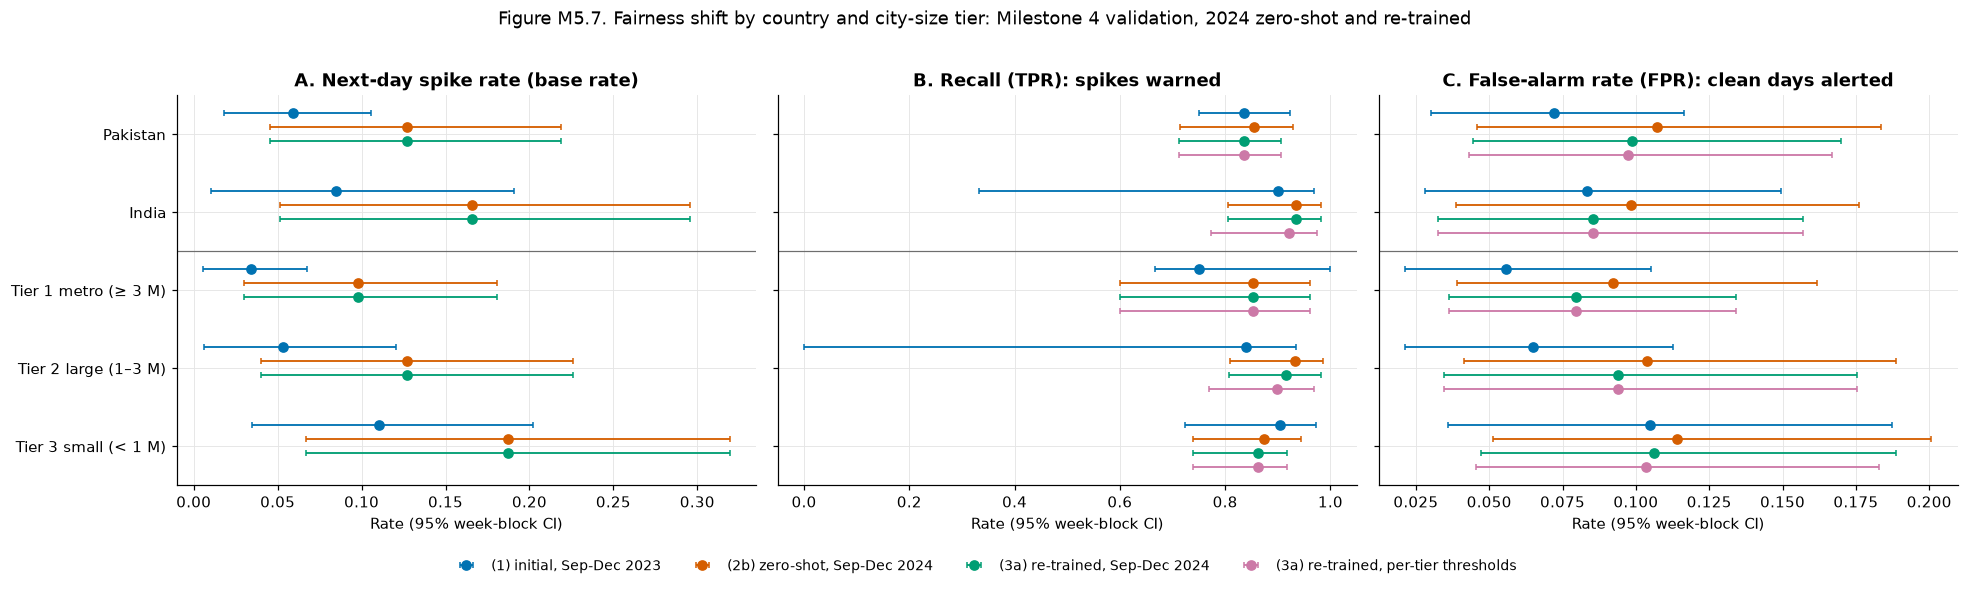

                             setting       grouping                group  cities  population_m  city_days  spike_days  person_days_exposed_m  missed_spike_days  missed_person_days_m  share_exposure_missed  false_alarm_days  false_alarm_person_days_m
           (1) initial, Sep-Dec 2023            all           all cities      11        28.678       1298          89                126.917                 12                20.813                  0.164                92                    183.225
           (1) initial, Sep-Dec 2023        country                India       4         3.869        472          40                 35.164                  4                 1.660                  0.047                36                     30.397
           (1) initial, Sep-Dec 2023        country             Pakistan       7        24.809        826          49                 91.753                  8                19.153                  0.209                56                    152.828


In [19]:
# Per-group TPR and FPR with week-block CIs (single threshold, LR full / re-trained final model)
ci_rows = []
for setting, fr, col_p in [("(1) initial, Sep-Dec 2023", s1, "p_lr_full|single threshold"),
                           ("(2b) zero-shot, Sep-Dec 2024", s2b, "p_lr_full|single threshold"),
                           ("(3a) re-trained, Sep-Dec 2024", te, f"p_{FINAL_RT}|single threshold"),
                           ("(3a) re-trained, per-tier thresholds", te, f"p_{FINAL_RT}|threshold per tier")]:
    for col in GROUPINGS:
        for g in sorted(fr[col].unique()):
            sub = fr[fr[col] == g]
            fn = lambda d: {k: v for k, v in FA._rates(d[TARGET], d[col_p]).items() if k in ("tpr", "fpr", "base_rate")}
            bbg = EV.block_bootstrap(sub, fn, n=N_BOOT, seed=42)
            for k, r in bbg.iterrows():
                ci_rows.append({"setting": setting, "grouping": GROUPINGS[col], "group": g, "metric": k,
                                "estimate": r.estimate, "ci_low": r.ci_low, "ci_high": r.ci_high})
group_ci = pd.DataFrame(ci_rows)
_ = save_table(group_ci, "m5_fair_group_ci", index=False)

# Figure M5.7
glist = ["Pakistan", "India"] + list(FA.TIER_LABEL.values())
SET_C = {"(1) initial, Sep-Dec 2023": P.CAT_COLORS[0], "(2b) zero-shot, Sep-Dec 2024": P.CAT_COLORS[1],
         "(3a) re-trained, Sep-Dec 2024": P.CAT_COLORS[2], "(3a) re-trained, per-tier thresholds": P.CAT_COLORS[4]}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), sharey=True)
for ax, metric, title in [(axes[0], "base_rate", "A. Next-day spike rate (base rate)"),
                          (axes[1], "tpr", "B. Recall (TPR): spikes warned"),
                          (axes[2], "fpr", "C. False-alarm rate (FPR): clean days alerted")]:
    for k, (setting, col) in enumerate(SET_C.items()):
        if metric == "base_rate" and "per-tier" in setting:
            continue
        d = group_ci[(group_ci.setting == setting) & (group_ci.metric == metric)].set_index("group").loc[glist]
        yv = np.arange(len(glist)) + (k - 1.5) * 0.18
        ax.errorbar(d.estimate, yv, xerr=[d.estimate - d.ci_low, d.ci_high - d.estimate], fmt="o", color=col, ms=6,
                    capsize=2, lw=1.2, label=setting)
    ax.axhline(1.5, color=P.GREY, lw=0.8)
    ax.set_yticks(range(len(glist))); ax.set_yticklabels(glist)
    ax.set(xlabel="Rate (95% week-block CI)", title=title)
axes[0].invert_yaxis()
h_, l_ = axes[1].get_legend_handles_labels()
fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.07))
fig.suptitle("Figure M5.7. Fairness shift by country and city-size tier: Milestone 4 validation, 2024 zero-shot and re-trained", y=1.02)
fig.tight_layout()
P.save(fig, "fig_m05_7_fairness_shift")
plt.show()

# Population exposure (census population x spike days), lite version of Extension 2
tiers = FA.load_city_tiers().set_index("city")
ex_rows = []
for setting, fr, col_p in [("(1) initial, Sep-Dec 2023", s1, "p_lr_full|single threshold"),
                           ("(2b) zero-shot, Sep-Dec 2024", s2b, "p_lr_full|single threshold"),
                           ("(2b) zero-shot, per-tier thresholds", s2b, "p_lr_full|threshold per tier"),
                           ("(3a) re-trained, Sep-Dec 2024", te, f"p_{FINAL_RT}|single threshold"),
                           ("(3a) re-trained, per-tier thresholds", te, f"p_{FINAL_RT}|threshold per tier")]:
    d = fr.assign(popn=fr.city.map(tiers.population), y=fr[TARGET], a=fr[col_p])
    for grouping, col in [("all", None), ("country", "country_name"), ("city-size tier", "tier")]:
        for g in (["all cities"] if col is None else sorted(d[col].unique())):
            s = d if col is None else d[d[col] == g]
            ex_rows.append({"setting": setting, "grouping": grouping, "group": g, "cities": s.city.nunique(),
                            "population_m": s.drop_duplicates("city")["popn"].sum() / 1e6, "city_days": len(s),
                            "spike_days": int(s.y.sum()), "person_days_exposed_m": (s["popn"] * s.y).sum() / 1e6,
                            "missed_spike_days": int(((s.y == 1) & (s.a == 0)).sum()),
                            "missed_person_days_m": (s["popn"] * ((s.y == 1) & (s.a == 0))).sum() / 1e6,
                            "share_exposure_missed": (s["popn"] * ((s.y == 1) & (s.a == 0))).sum() / max((s["popn"] * s.y).sum(), 1),
                            "false_alarm_days": int(((s.y == 0) & (s.a == 1)).sum()),
                            "false_alarm_person_days_m": (s["popn"] * ((s.y == 0) & (s.a == 1))).sum() / 1e6})
exposure = pd.DataFrame(ex_rows)
_ = save_table(exposure, "m5_exposure", index=False)
print(exposure.round(3).to_string(index=False))

**What we found (M5.9)**

- **Under one threshold, no fairness gap changed beyond its uncertainty.** Every paired re-trained − zero-shot difference (EO, ΔTPR, ΔFPR, DP, DIR, by country and by tier) has a 95% CI that includes 0.
- **The false-alarm rate rose in every tier on 2024.** Zero-shot, it went from 5.6% to 9.2% in metros and from 10.5% to 11.4% in small cities.
- **The tier DIR still fails the 80% rule, and it follows the base rates.** In Sep–Dec 2024, Tier 3 had 18.8% spike days against 9.8% in metros.
- **The per-tier thresholds lose their small-city adjustment.** In Milestone 4 they ranged from 0.128 to 0.160, with the highest for Tier 3. Re-chosen on the combined data they range from 0.174 to 0.180. Their tier DIR is higher than with the Milestone 4 tier thresholds by 0.110 [0.018, 0.301].
- **Exposure (lite Extension 2).** The 180 spike days of Sep–Dec 2024 add up to 295 million person-days. The zero-shot alert missed 10.6% of them (31.4 million). The three Pakistani metros hold 58% of the missed person-days.

---
## M5.10 Sensitivity: spike thresholds re-learned on the expanded training rows

- **New rule:** each city's threshold becomes its P90 over the Oct–Mar days of the expanded training period (2022-08-04 → 2024-08-31, suspect days left out). The labels, the AQ-history margins and persistence then follow the new thresholds.
- **Models:** LR full is re-tuned with the Milestone 3 grid and scored on Sep–Dec 2024, next to persistence.

In [20]:
aq5 = pd.read_parquet(C.M5_CLEAN_DIR / "aq_daily.parquet")
mask = IG.aq_train_mask(aq5, C.M5_TRAIN_START, C.M5_TRAIN_END) & aq5.date.dt.month.isin(IG.WINTER_MONTHS)
thr_new = aq5[mask].groupby("city")["composite_smog_index"].quantile(0.90)
thr_tab = pd.DataFrame({"threshold_frozen": pd.Series(frozen["aq"]["spike_threshold_mean_index"]),
                        "threshold_relearned": thr_new}).rename_axis("city").reset_index()
thr_tab["change"] = thr_tab.threshold_relearned - thr_tab.threshold_frozen
_ = save_table(thr_tab, "m5_label_relearned_thresholds", index=False)
print(thr_tab.round(4).to_string(index=False))


def relabel(fr):
    out = fr.copy()
    t = out.city.map(thr_new)
    out[TARGET] = (out["target_index_h1"] >= t).astype(int)
    out["spike_threshold"] = t
    for mcol, raw in zip(MD.AQ_HISTORY, MD.AQ_HISTORY_RAW):
        out[mcol] = out[raw] - t
    out["persist_spike"] = (out["persist_index"] >= t).astype(int)
    return out


tr_r, te_r = relabel(train), relabel(test)
y_tr_r, y_te_r = tr_r[TARGET].to_numpy(), te_r[TARGET].to_numpy()
assert_train_only(tr_r)
splits_r = MD.purged_sgkf_splits(tr_r, y_tr_r, n_splits=5, seeds=SEEDS, horizon=H)
gs_r = MD.tune(MD.make_lr(MD.FEATURE_SETS["full"]), MD.LR_GRID, tr_r[MD.FEATURE_SETS["full"]], y_tr_r, splits_r)
oof_r, _ = MD.oof_predict(gs_r.best_estimator_, tr_r[MD.FEATURE_SETS["full"]], y_tr_r, splits_r)
thr_r, _ = MD.choose_threshold(y_tr_r, oof_r, COST_FN, COST_FP)
s_r = gs_r.best_estimator_.predict_proba(te_r[MD.FEATURE_SETS["full"]])[:, 1]
tier_thr_r = FA.group_thresholds(y_tr_r, oof_r, tr_r.tier.to_numpy(), COST_FN, COST_FP)
ps_r, py_r = MD.persistence(te_r)
rows = []
for label_rule, y_train, y_test, models in [
        ("frozen (2022-23 training)", y_tr, y_te,
         {"Persistence": (te["s_persistence"], te["p_persistence"]),
          f"{LABEL[FINAL_RT]} (re-trained)": (te[f"s_{FINAL_RT}"], te[f"p_{FINAL_RT}"]),
          f"{LABEL[FINAL_RT]}, per-tier thresholds": (te[f"s_{FINAL_RT}"], te[f"p_{FINAL_RT}|threshold per tier"])}),
        ("re-learned (to 2024-08-31)", y_tr_r, y_te_r,
         {"Persistence": (ps_r, py_r), "LR full (re-trained)": (s_r, (s_r >= thr_r).astype(int)),
          "LR full, per-tier thresholds": (s_r, FA.apply_thresholds(s_r, te_r.tier, tier_thr_r))})]:
    for mname, (s, p) in models.items():
        r = EV.binary_metrics(y_test, s, yhat=p)
        dsp = FA.disparity(FA.group_metrics(y_test, p, te.tier), PRIV["tier"])
        rows.append({"label_rule": label_rule, "model": mname, "train_spike_rate": y_train.mean(),
                     "test_spike_rate": y_test.mean(), "test_spikes": int(y_test.sum()),
                     **{k: r[k] for k in ["recall", "precision", "f1", "roc_auc", "pr_auc", "cost_per_1000"]},
                     "tier_dir_vs_priv_max": dsp["dir_vs_priv_max"], "tier_pe_diff": dsp["pe_diff"], "tier_eo_diff": dsp["eo_diff"]})
relearn = pd.DataFrame(rows)
_ = save_table(relearn, "m5_label_relearned", index=False)
print()
print(relearn.round(4).to_string(index=False))
print("Re-learned-label LR full:", {k.replace("model__", ""): v for k, v in gs_r.best_params_.items()},
      f"CV PR-AUC {gs_r.best_score_:.4f}, threshold {thr_r:.4f}")

          city  threshold_frozen  threshold_relearned  change
      Amritsar            1.6402               1.6352 -0.0050
    Faisalabad            1.5878               1.7738  0.1859
     Ferozepur            1.2452               1.3603  0.1151
     Islamabad            0.6543               0.5989 -0.0554
     Jalandhar            1.0862               1.2615  0.1753
        Lahore            2.1771               1.9899 -0.1871
      Ludhiana            1.1731               1.2477  0.0746
        Multan            1.2505               1.3778  0.1273
Rahim Yar Khan            0.3631               0.5864  0.2232
    Rawalpindi            0.6543               0.5989 -0.0554
       Sialkot            1.3364               1.3247 -0.0117



                label_rule                        model  train_spike_rate  test_spike_rate  test_spikes  recall  precision     f1  roc_auc  pr_auc  cost_per_1000  tier_dir_vs_priv_max  tier_pe_diff  tier_eo_diff
 frozen (2022-23 training)                  Persistence            0.0584           0.1411          180  0.7111     0.7151 0.7131   0.9467  0.7304       243.7304                1.9191        0.0265        0.0861
 frozen (2022-23 training)         LR full (re-trained)            0.0584           0.1411          180  0.8778     0.6054 0.7166   0.9461  0.7277       166.9279                1.5972        0.0265        0.0623
 frozen (2022-23 training) LR full, per-tier thresholds            0.0584           0.1411          180  0.8722     0.6062 0.7153   0.9461  0.7277       170.0627                1.5833        0.0238        0.0454
re-learned (to 2024-08-31)                  Persistence            0.0521           0.1176          150  0.6333     0.6376 0.6355   0.9390  0.6139     

**What we found (M5.10)**

- **Re-learned thresholds move by −0.19 to +0.22.** Rahim Yar Khan rises the most and Lahore falls the most.
- **The re-learned label has fewer spikes.** The test spike rate falls from 14.1% to 11.8% (150 spikes instead of 180).
- **Ranking skill drops under the re-learned label.** Re-trained LR full scores PR-AUC 0.611 and persistence 0.614. The cost per 1,000 city-days is 154.4.
- **We keep the frozen label as the headline.** A moving threshold hides part of the 2024 deterioration, and it changes the meaning of "spike" between years.

---
## M5.11 Saved models and parameters

In [21]:
import platform
import scipy
import sklearn
import statsmodels

for m in RT_MODELS:
    if m != "persistence":
        joblib.dump(rt_fitted[m], f"models/m5_{m}.joblib")
to_py = lambda v: None if v is None else (float(v) if isinstance(v, (float, np.floating)) else
                                          int(v) if isinstance(v, (int, np.integer)) else v)
params = {
    "target": TARGET, "cost_fn_fp": [COST_FN, COST_FP], "fast_run": FAST,
    "windows": {"raw": [C.M5_RAW_START, C.M5_WINDOW_END], "model": [C.M5_WINDOW_START, C.M5_WINDOW_END],
                "new_wave_start": C.NEW_WAVE_START, "seal": C.SEAL_M5,
                "retrain_train": [C.M5_TRAIN_START, C.M5_TRAIN_END], "skip": [C.M5_SKIP_START, C.M5_SKIP_END],
                "test": [C.M5_TEST_START, C.M5_TEST_END]},
    "frozen_parameters": ["aq_params.json", "weather_zscore_params.json", "fire_zscore_params.json", "role2_params.json"],
    "dims": dims.astype(str).to_dict(orient="records"),
    "fire_gap_days": [d.strftime("%Y-%m-%d") for d in gap_dates],
    "drift": {"psi_bins": 10, "psi_eps": DR.PSI_EPS, "psi_bands": {"stable": "< 0.10", "moderate": "0.10-0.25", "major": ">= 0.25"},
              "multiple_testing": "Benjamini-Hochberg", "season_matched_months": SEASON,
              "concept_test_sample": "Sep-Feb, rain_day == 0", "concept_terms": TERMS},
    "cv": {"type": "purged repeated StratifiedGroupKFold", "n_splits": 5, "seeds": list(SEEDS)},
    "search": {"n_iter": N_ITER, "seed": 42, "scoring": "average_precision"},
    "models": {m: {"best_params": {k.replace("model__", ""): to_py(v) for k, v in searches[m].best_params_.items()},
                   "cv_pr_auc": rt_cv[m], "threshold": rt_thr[m]} for m in searches},
    "final_model_rule": m4["final_model_rule"], "final_model": FINAL_RT, "best_ensemble": BEST_ADV_RT,
    "final_model_thresholds": RULES_RT,
    "relearned_label": {"thresholds": {c: float(v) for c, v in thr_new.items()}, "lr_full_threshold": thr_r,
                        "lr_full_best_params": {k.replace("model__", ""): to_py(v) for k, v in gs_r.best_params_.items()}},
}
(C.CLEAN_DIR / "m5_params.json").write_text(json.dumps(params, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved:", sorted(p.name for p in Path("models").glob("m5_*.joblib")))
print(f"Python {platform.python_version()}, numpy {np.__version__}, pandas {pd.__version__}, scipy {scipy.__version__}, "
      f"scikit-learn {sklearn.__version__}, statsmodels {statsmodels.__version__}, joblib {joblib.__version__}")
print(f"Total run time: {time.time() - T0:.0f} s")

Saved: ['m5_dt_full.joblib', 'm5_dt_no_fire.joblib', 'm5_dt_weather_only.joblib', 'm5_hgb_full.joblib', 'm5_hgb_no_fire.joblib', 'm5_lr_full.joblib', 'm5_lr_no_fire.joblib', 'm5_lr_weather_only.joblib', 'm5_majority.joblib', 'm5_rf_full.joblib', 'm5_rf_no_fire.joblib']
Python 3.14.6, numpy 2.5.4, pandas 3.1.0, scipy 1.18.1, scikit-learn 1.9.1, statsmodels 0.15.0, joblib 1.6.0
Total run time: 4817 s


---
## Summary

**Ingestion.** One module (`src/ingest.py`) rebuilds every daily table from the raw files with the frozen 2022–23 parameters. It reproduces the committed 2022–23 tables exactly. The 2024 wave adds 4,004 city-days, so N_total = 9,669 and P_total = 291.

**Drift.**
- *Covariate:* most features shift little (PSI < 0.10). Fires within 300 km fell sharply in Sep–Dec 2024 (PSI 0.401). The domain classifier separates the waves weakly (ROC-AUC 0.531 whole wave, 0.645 season-matched).
- *Label:* the next-day spike rate rose from 5.4% to 9.1%, and November rose from 4.5% to 27.6%.
- *Concept:* the stagnation and fire effects changed (LR test p 0.002). The frozen LR under-predicts the 2024 spike rate.

**Three-way audit (LR full, PR-AUC / cost per 1,000 city-days).**

| Setting | PR-AUC | Cost |
|---|---|---|
| (1) Initial model, Sep–Dec 2023 | 0.695 | 117.1 |
| (2b) Zero-shot, Sep–Dec 2024 | 0.726 | 167.7 |
| (3a) Re-trained, Sep–Dec 2024 | 0.728 | 166.9 |
| (3b) Re-trained, combined purged CV | 0.727 | 95.7 |

Full metrics (accuracy, precision, recall, F1, ROC-AUC) are in `m5_three_way_wide.csv`. Ranking skill held out of time. The cost of errors grew with the spike rate. Re-training did not change the final model's skill, and LR full stays the final model.

**Fairness.** Under one threshold, no gap between countries or tiers changed beyond its uncertainty. Per-tier thresholds re-chosen on the combined data nearly converge, so they lose their small-city adjustment.

**For the paper.** All tables are in `docs/tables/m5_*.csv`, figures in `figures/fig_m05_*.png`. The decisions are rows N1–N16 in `DECISIONS.md`.